[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/artkula/ML-retreat-tekmek-2026/blob/main/2-GAN_PINN/GANs_PINNs_handson.ipynb)

# GANs and PINNs: learning from examples and from physics
**AI retreat · Department of Engineering Mechanics, KTH · Marco Laudato · 13 October 2026**

Two questions guide this **80-minute hands-on session**:

- **GANs:** can we learn the variation across tensile specimens and generate a new stress–strain curve?
- **PINNs:** can we predict acoustic pressure in a cavity using its governing equation, and then infer wave speed from two sensors?

We begin each case with its physics, run short examples together, and change parameters to test our expectations.

> **Our working rule:** predict → run → inspect → explain. An unexpected result is evidence to investigate.

## One notebook, one continuous session

| Part | Time | Explore |
|---|---:|---|
| [A · GANs: a virtual collection of tensile tests](#part-a) | 40 min | Alternating updates, family coverage, latent space and a discriminator's judgement |
| [B · PINNs: pressure in an acoustic cavity](#part-b) | 40 min | Input derivatives, physics losses, wall conditions and an unknown wave speed |
| [Optional experiments and runtime notes](#optional-experiments) | After the session | Further tests and the measured CPU timings |

Upload **this single `.ipynb`** at [Google Colab](https://colab.research.google.com/), choose a Python runtime, and use CPU. Run cells from top to bottom with **Shift+Enter**. No external dataset, trained weights or GPU is needed; diagrams and reference outputs are included.

**Keep the same runtime for both parts. No restart or variable clearing is needed.** The networks and datasets are small. Each training call starts its own seeded model, and the GAN models and sliders remain available while we work on PINNs. If you later start directly at Part B in a fresh runtime, run the shared setup cell below first, then run Part B in order.

Sliders evaluate a formula or a trained model; they do not launch training. Training happens only in the marked cells. During exercises, change one parameter, state your expectation, then rerun the indicated cells.

### Shared setup · run once for both parts

Colab normally has these packages. The cell installs only missing ones. Installation depends on the environment; the training timings reported at the end exclude installation.

In [1]:
# Install only missing packages. No dataset download is needed.
import importlib.util, subprocess, sys
packages = {"numpy": "numpy", "matplotlib": "matplotlib", "torch": "torch",
            "ipywidgets": "ipywidgets"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import time, math
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, HTML, Markdown
import ipywidgets as widgets

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

torch.set_num_threads(1)  # Small matrix operations often benefit from one CPU thread.
DEVICE = torch.device("cpu")
DATA_SEED, MODEL_SEED, SAMPLE_SEED = 2026, 42, 100
BLUE, ORANGE, PURPLE, INK = "#004791", "#c46924", "#8053a0", "#182d46"
plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": INK, "text.color": INK,
                     "figure.facecolor": "white", "axes.facecolor": "white"})
print(f"PyTorch {torch.__version__} · device: {DEVICE} · threads: {torch.get_num_threads()}")
print("Ready for both parts. Keep this runtime running throughout the session.")

PyTorch 2.6.0+cpu · device: cpu · threads: 1
Ready for both parts. Keep this runtime running throughout the session.


<a id="part-a"></a>

# Part A · GANs: a virtual collection of tensile tests
Imagine receiving a folder of stress–strain curves from many specimens. Could a neural network generate another specimen with a similar response? Could it also learn the **variation across specimens**?

In this hands-on, we train a **generative adversarial network (GAN)**, explore its two-dimensional latent space, and ask its discriminator to judge a curve we have made ourselves.

**First half of the session · about 40 minutes.** Continue directly to Part B afterwards.

## Part A · route through the next 40 minutes

| Activity | Minutes |
|---|---:|
| Recall the GAN idea | 2 |
| Understand a tensile test and change its parameters | 6 |
| Construct and inspect the specimen collection | 3 |
| Inspect the networks and perform the two updates | 6 |
| Train the GAN and watch its progress | 3 |
| Check the population and the physics | 4 |
| Explore latent space | 5 |
| Change one training parameter and discuss | 5 |
| Make your own curve and ask D to judge it | 4 |
| Takeaways | 2 |

## A1. A GAN learns to generate a population

The **generator G** receives random numbers $\mathbf z$ and returns a candidate sample. The **discriminator D** sees a sample and scores whether it resembles the reference dataset. G learns from D's feedback; D learns from reference and generated examples.

In the lecture, a sample was a point $(x,y)$ and success meant covering eight clusters. Here a sample will be an entire stress–strain curve, and we will check whether both specimen families appear.

The CNN autoencoder encoded an existing field and reconstructed it. This generator starts from random input. There is **no encoder** in this exercise, and no known material meaning is assigned to either latent coordinate.

**“Real” will mean “from our synthetic reference dataset”.** D's score describes learned resemblance to that dataset. It does not certify that a curve satisfies mechanics.

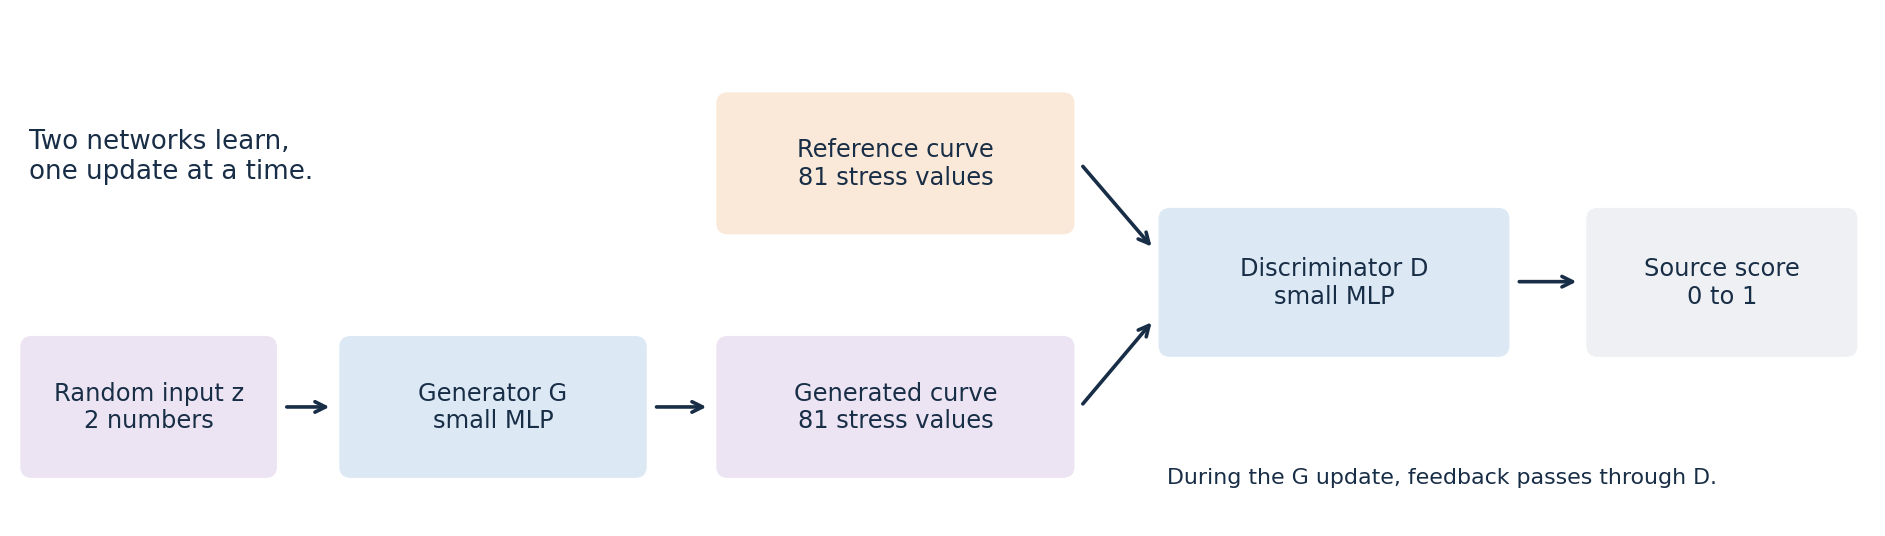

## A2. Physics first: what does a tensile test measure?

We pull a specimen slowly in one direction. Its original gauge length is $L_0$ and its original cross-sectional area is $A_0$. The force is $F$ and the extension is $\Delta L$.

$$\text{Engineering strain: }\varepsilon=\frac{\Delta L}{L_0},\qquad
\text{Engineering stress: }\sigma=\frac{F}{A_0}.$$

Strain is dimensionless. **1% strain is 0.01 in the equations.** Stress has units of pressure; our plots use MPa.

At first, the response is elastic: removing the force would recover the deformation. At **yield**, permanent deformation begins. Further loading can require increasing stress because the material **hardens**.

We model only the loading branch: uniform uniaxial tension, a quasi-static response, no temperature or rate effects, and no measurement noise. We omit unloading, necking and fracture. This simple law is a teaching model, not a full constitutive description of a particular material.

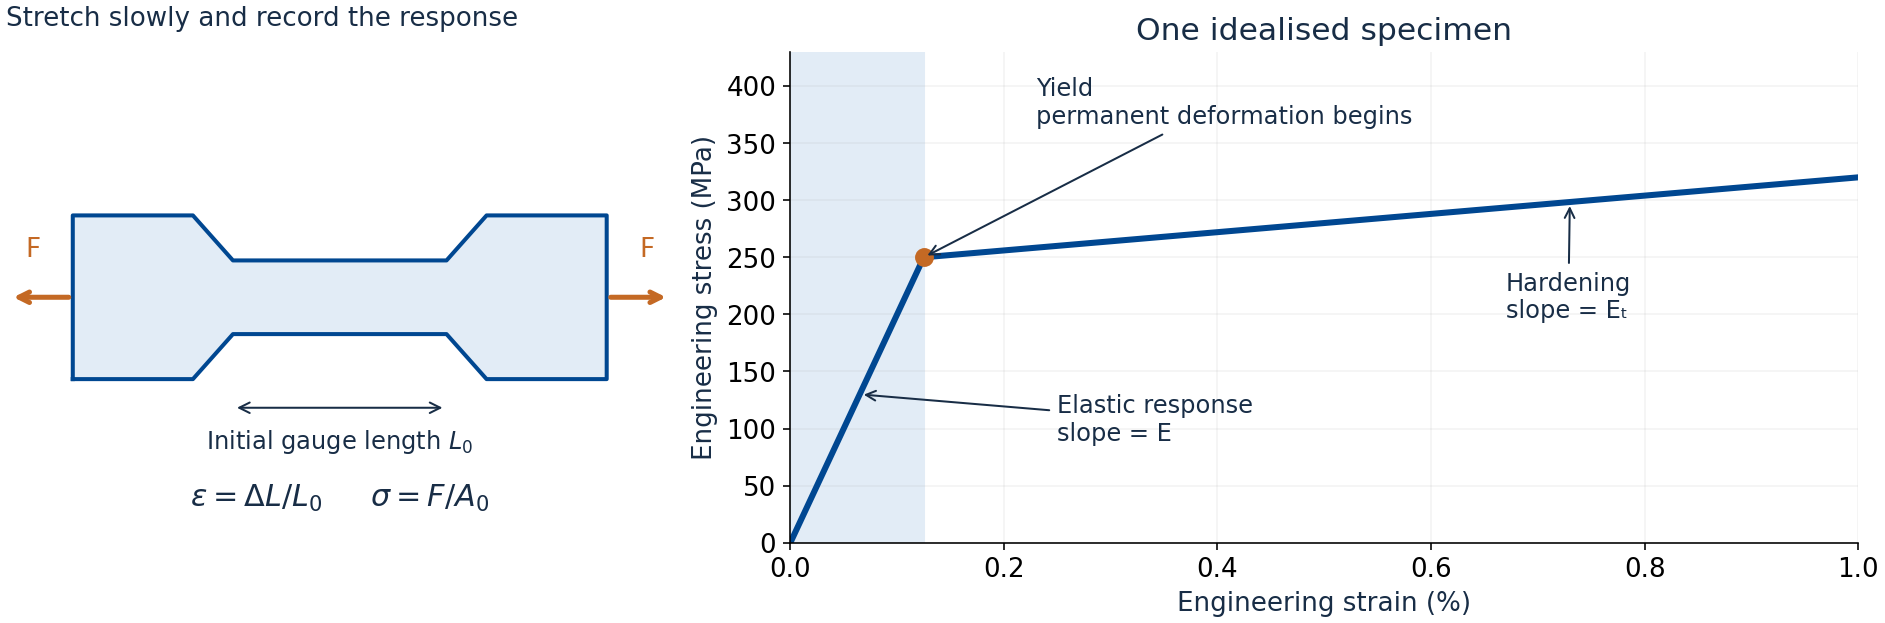

### A bilinear loading law

$$\varepsilon_y=\frac{\sigma_y}{E},\qquad
\sigma(\varepsilon)=
\begin{cases}
E\varepsilon, & \varepsilon\leq\varepsilon_y,\\
\sigma_y+E_t(\varepsilon-\varepsilon_y), & \varepsilon>\varepsilon_y.
\end{cases}$$

| Symbol | Meaning | Value or unit |
|---|---|---|
| $E$ | Young's modulus: initial elastic slope | 200 GPa = 200,000 MPa |
| $\sigma_y$ | Stress at the start of yielding | MPa |
| $\varepsilon_y$ | Strain at yield | dimensionless |
| $E_t$ | **Post-yield tangent slope** $d\sigma/d\varepsilon$ | GPa, converted to MPa in code |

Both branches meet at $(\varepsilon_y,\sigma_y)$, so stress is continuous. $E_t$ describes the slope with respect to **total strain** after yield. It is not a second Young's modulus and is not the plastic hardening modulus with respect to plastic strain.

For $\sigma_y=250$ MPa, yield begins at $250/200000=0.00125$, or **0.125% strain**. With $E_t=8$ GPa, the stress at 1% strain is **320 MPa**.

In [2]:
E_MPA = 200_000.0
strain = np.linspace(0.0, 0.01, 81, dtype=np.float32)

def bilinear(strain_values, yield_mpa, tangent_gpa):
    """Stress in MPa for dimensionless strain; accepts scalar or array parameters."""
    yield_strain = np.asarray(yield_mpa) / E_MPA
    tangent_mpa = 1000.0 * np.asarray(tangent_gpa)
    return np.where(strain_values <= yield_strain,
                    E_MPA * strain_values,
                    yield_mpa + tangent_mpa * (strain_values - yield_strain))

def curve_axes(ax, title, zoom=False):
    ax.set(title=title, xlabel="Engineering strain (%)", ylabel="Engineering stress (MPa)")
    ax.set_xlim(0, 0.30 if zoom else 1.0)
    ax.grid(alpha=0.18)

print(f"Grid: {len(strain)} points, spacing {100 * (strain[1]-strain[0]):.4f}% strain")
print(f"Stress at 1% strain for the example: {bilinear(.01, 250, 8):.1f} MPa")

Grid: 81 points, spacing 0.0125% strain
Stress at 1% strain for the example: 320.0 MPa


### Exercise 1 · predict, then change the specimen

1. Keep the tangent slope fixed. Change the yield stress from **250 to 450 MPa**. Does the initial slope change? Does yield move left or right?
2. Restore 250 MPa. Change the tangent slope from **8 to 2 GPa**. Does the yield point move?

Change the two values below and rerun **only this cell**. This illustration does not alter the training dataset that we construct next.

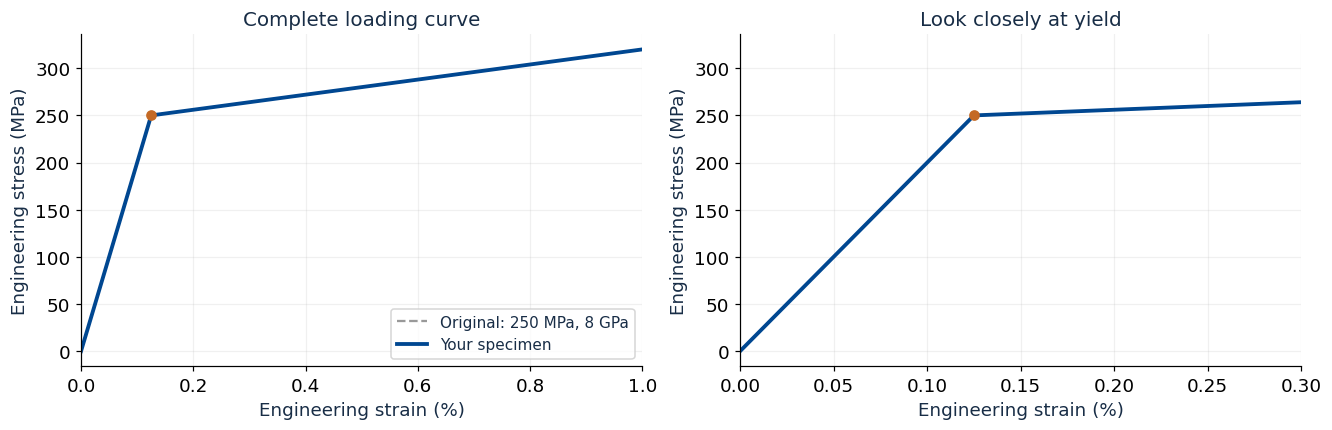

Yield strain: 0.125% · stress at 1%: 320.0 MPa


In [3]:
# YOUR TWO PHYSICAL KNOBS
YIELD_MPA = 250.0
TANGENT_GPA = 8.0

assert 0 < YIELD_MPA < E_MPA * strain[-1], "Choose a yield point inside our strain range."
assert 0 <= TANGENT_GPA < E_MPA / 1000, "Use a nonnegative slope smaller than E."
specimen = bilinear(strain, YIELD_MPA, TANGENT_GPA)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, zoom in zip(axes, [False, True]):
    ax.plot(100 * strain, bilinear(strain, 250, 8), "--", color="0.6", label="Original: 250 MPa, 8 GPa")
    ax.plot(100 * strain, specimen, color=BLUE, lw=2.5, label="Your specimen")
    ax.scatter([100 * YIELD_MPA / E_MPA], [YIELD_MPA], color=ORANGE, zorder=4)
    curve_axes(ax, "Complete loading curve" if not zoom else "Look closely at yield", zoom)
axes[0].legend(fontsize=10)
plt.show()
print(f"Yield strain: {100 * YIELD_MPA / E_MPA:.3f}% · stress at 1%: {specimen[-1]:.1f} MPa")

<details><summary><b>After discussing: suggested interpretation</b></summary>

Increasing yield stress delays yield to a larger strain. The initial slope stays at 200 GPa. Changing the post-yield tangent slope changes the loading curve only after yield; it leaves the yield point unchanged. Because we have no unloading branch, we do not simulate the permanent strain after removing the force.

</details>

## A3. A collection of specimens

We create two equally common synthetic families. Within each family, we draw yield stress and tangent slope independently from uniform ranges.

| Family | Yield stress | Post-yield tangent slope | Interpretation |
|---|---|---|---|
| A · blue | 220–280 MPa | 6–10 GPa | Yields earlier, then hardens more strongly |
| B · orange | 420–480 MPa | 1–3 GPa | Yields later, then hardens more weakly |

These labels identify our synthetic construction. They are not names of material grades.

We make **2,000 specimens**: 1,600 for training and 400 held aside for checking results. Both sets contain equal numbers from A and B. We retain the family labels for plots, but **neither G nor D receives those labels or the material parameters**.

In [4]:
rng = np.random.default_rng(DATA_SEED)
family = np.repeat([0, 1], 1000)
yield_mpa = np.where(family == 0, rng.uniform(220, 280, 2000),
                    rng.uniform(420, 480, 2000))
tangent_gpa = np.where(family == 0, rng.uniform(6, 10, 2000),
                      rng.uniform(1, 3, 2000))
all_curves = bilinear(strain[None, :], yield_mpa[:, None],
                      tangent_gpa[:, None]).astype(np.float32)

# Split specimens within each family, so both sets are balanced.
train_ids, check_ids = [], []
for label in [0, 1]:
    ids = rng.permutation(np.flatnonzero(family == label))
    train_ids.extend(ids[:800])
    check_ids.extend(ids[800:])
train_ids, check_ids = np.array(train_ids), np.array(check_ids)
train_curves, check_curves = all_curves[train_ids], all_curves[check_ids]
train_family, check_family = family[train_ids], family[check_ids]
print(f"Training array: {train_curves.shape} = (specimens, stress values per specimen)")
print(f"Held-aside array: {check_curves.shape}")

Training array: (1600, 81) = (specimens, stress values per specimen)
Held-aside array: (400, 81)


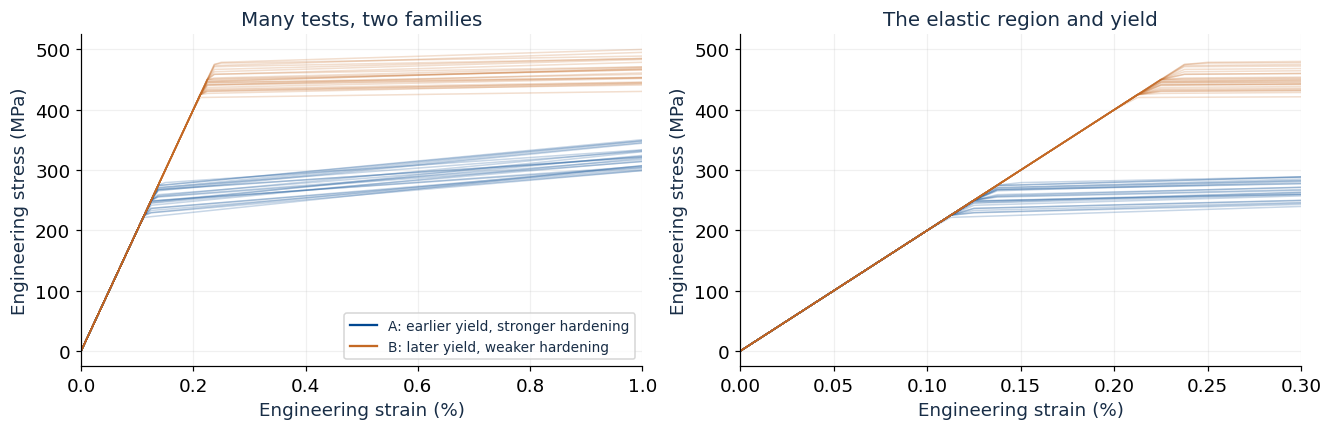

One row is one complete curve. A batch of 128 contains 128 curves, not 128 strain points.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for label, color, name in [(0, BLUE, "A: earlier yield, stronger hardening"),
                            (1, ORANGE, "B: later yield, weaker hardening")]:
    examples = train_curves[train_family == label][:25]
    for ax in axes:
        ax.plot(100 * strain, examples.T, color=color, alpha=.22, lw=1)
        ax.plot([], [], color=color, label=name)
curve_axes(axes[0], "Many tests, two families")
curve_axes(axes[1], "The elastic region and yield", zoom=True)
axes[0].legend(fontsize=9)
plt.show()
print("One row is one complete curve. A batch of 128 contains 128 curves, not 128 strain points.")

### Convert stress values into convenient network inputs

Networks train more easily when numerical scales are comparable. At each strain point $j$, we subtract the **training-set mean** and divide by the training-set standard deviation:

$$x_j=\frac{\sigma_j-\mu_j}{s_j},\qquad \sigma_j=\mu_j+s_jx_j.$$

All reference specimens share the earliest elastic response, so its standard deviation is almost zero. We set a **10 MPa minimum scale** to avoid dividing by zero or amplifying tiny numbers. This is a numerical scaling choice, not a physical tolerance.

This transformation is invertible and keeps **all 81 coordinates**. There is no POD, curve fitting, or dimensionality reduction. G outputs 81 scaled stress values, which we convert directly back to MPa. No law forces the generated elastic slope or curve shape to be correct.

In [6]:
stress_mean = train_curves.mean(axis=0)
stress_scale = np.maximum(train_curves.std(axis=0), 10.0)

def to_network(curves_mpa):
    return torch.as_tensor((np.asarray(curves_mpa) - stress_mean) / stress_scale,
                           dtype=torch.float32, device=DEVICE)

def to_mpa(values):
    return values.detach().cpu().numpy() * stress_scale + stress_mean

train_tensor = to_network(train_curves)
print(f"The discriminator's input batch has shape {tuple(train_tensor[:128].shape)}.")
print(f"Scaling round-trip error: {np.max(np.abs(to_mpa(train_tensor)-train_curves)):.5f} MPa")

The discriminator's input batch has shape (128, 81).
Scaling round-trip error: 0.00002 MPa


## A4. Two small networks

| Network | Input | Hidden layers | Output |
|---|---|---|---|
| G | Two random numbers $(z_1,z_2)$ | 64 neurons, then 64 neurons | 81 scaled stress values |
| D | One complete scaled curve | 64 neurons, then 64 neurons | One **logit**, an unrestricted number |

G uses smooth `Tanh` activations inside the network and a linear output. D uses `LeakyReLU`, which keeps a small slope on the negative side, and a linear output. These are ordinary multilayer perceptrons (MLPs).

For display, we transform D's logit with a sigmoid to get a score between 0 and 1. During training, `BCEWithLogitsLoss` includes that sigmoid internally. Applying a sigmoid again before this loss would be incorrect.

Each latent coordinate is drawn from a standard normal distribution, $z_i\sim\mathcal N(0,1)$. The two inputs provide variation; they are **not prescribed yield stress and hardening**.

In [7]:
def make_models(seed=MODEL_SEED, g_lr=2e-4, d_lr=1e-3):
    torch.manual_seed(seed)
    G = nn.Sequential(nn.Linear(2, 64), nn.Tanh(),
                      nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 81)).to(DEVICE)
    D = nn.Sequential(nn.Linear(81, 64), nn.LeakyReLU(.2),
                      nn.Linear(64, 64), nn.LeakyReLU(.2), nn.Linear(64, 1)).to(DEVICE)
    opt_g = torch.optim.Adam(G.parameters(), lr=g_lr, betas=(.5, .999))
    opt_d = torch.optim.Adam(D.parameters(), lr=d_lr, betas=(.5, .999))
    return G, D, opt_g, opt_d

G_demo, D_demo, opt_g_demo, opt_d_demo = make_models()
loss_function = nn.BCEWithLogitsLoss()
for name, model in [("G", G_demo), ("D", D_demo)]:
    print(f"{name}: {sum(p.numel() for p in model.parameters()):,} trainable parameters")

G: 9,617 trainable parameters
D: 9,473 trainable parameters


### Before learning: can the random network already draw a curve?

Yes, it produces 81 numbers. Whether those numbers form a good specimen is another question. The inverse scaling adds the dataset mean, so the initial curves may already have a broadly recognisable shape. That comes from preprocessing and should not be mistaken for learned diversity.

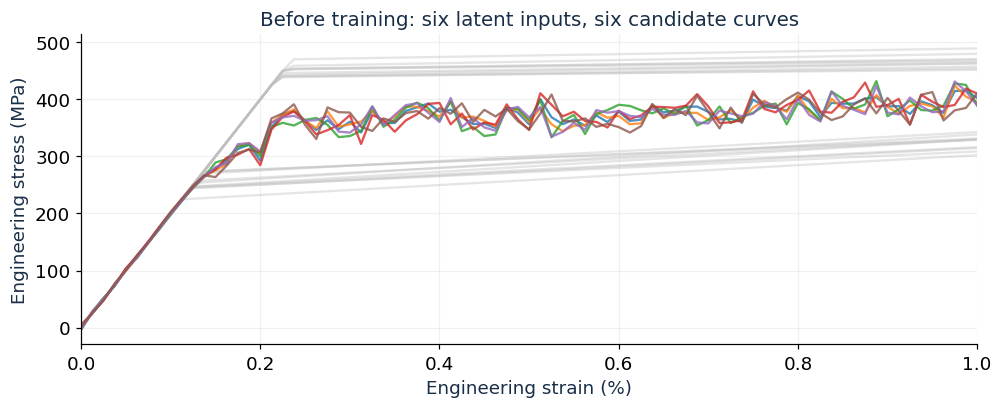

In [8]:
with torch.no_grad():
    untrained = to_mpa(G_demo(torch.randn(6, 2)))
fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
ax.plot(100 * strain, check_curves[::20].T, color="0.75", alpha=.4)
ax.plot(100 * strain, untrained.T, lw=1.5, alpha=.8)
curve_axes(ax, "Before training: six latent inputs, six candidate curves")
plt.show()

### One update cycle, slowed down

**Step D:** reference curves have target 1, generated curves have target 0. Change D's weights while keeping G fixed.

$$L_D=\mathrm{BCE}(D(x_\mathrm{ref}),1)+\mathrm{BCE}(D(G(z)),0).$$

Here the formula uses logits inside BCE. We detach generated curves from G's computation graph, so the D loss does not backpropagate into G.

**Step G:** draw fresh random inputs. Change G so that its generated curves receive higher scores from D.

$$L_G=\mathrm{BCE}(D(G(z)),1).$$

This is the usual non-saturating generator objective. The target 1 expresses G's aim; it does not relabel a generated curve as a reference sample. D's weights stay fixed, but gradients must still pass **through D** back to G.

> **Predict:** which network's weights will move in the next cell? Which will move in the cell after it?

In [9]:
def discriminator_step(G, D, optimizer, reference_batch):
    optimizer.zero_grad(set_to_none=True)
    z = torch.randn(len(reference_batch), 2, device=DEVICE)
    fake = G(z).detach()                       # Stop the gradient before G.
    real_logits, fake_logits = D(reference_batch), D(fake)
    loss = (loss_function(real_logits, torch.ones_like(real_logits))
            + loss_function(fake_logits, torch.zeros_like(fake_logits)))
    loss.backward()
    optimizer.step()                           # This optimizer owns only D's weights.
    return loss.item()

def weights(model):
    return torch.cat([p.detach().flatten() for p in model.parameters()]).clone()

g_before, d_before = weights(G_demo), weights(D_demo)
demo_d_loss = discriminator_step(G_demo, D_demo, opt_d_demo, train_tensor[::12])
print(f"After the D update: change in G = {torch.norm(weights(G_demo)-g_before):.6f}")
print(f"                    change in D = {torch.norm(weights(D_demo)-d_before):.6f}")

After the D update: change in G = 0.000000
                    change in D = 0.097324


In [10]:
def generator_step(G, D, optimizer, batch_size):
    for parameter in D.parameters():
        parameter.requires_grad_(False)        # Freeze D's weights, not the path through D.
    optimizer.zero_grad(set_to_none=True)
    z = torch.randn(batch_size, 2, device=DEVICE)
    fake_logits = D(G(z))                      # No detach and no no_grad here!
    loss = loss_function(fake_logits, torch.ones_like(fake_logits))
    loss.backward()
    optimizer.step()                           # This optimizer owns only G's weights.
    for parameter in D.parameters():
        parameter.requires_grad_(True)         # Ready for the next D update.
    return loss.item()

g_before, d_before = weights(G_demo), weights(D_demo)
demo_g_loss = generator_step(G_demo, D_demo, opt_g_demo, 128)
print(f"After the G update: change in G = {torch.norm(weights(G_demo)-g_before):.6f}")
print(f"                    change in D = {torch.norm(weights(D_demo)-d_before):.6f}")

After the G update: change in G = 0.019611
                    change in D = 0.000000


<details><summary><b>After discussing: what does “fixed D” mean?</b></summary>

Its weights do not change during the G update. Its output can change because G produces different inputs. We still differentiate that output with respect to the generated curve. Detaching G's output or putting D inside `torch.no_grad()` in this step would break the feedback G needs.

</details>

## A5. Repeat the competition

One **update cycle** below contains one D minibatch update followed by one G minibatch update. We randomly sample batches of 128 with replacement. A cycle is not an epoch, and no generated curve is paired with a particular reference curve.

The function starts fresh models every time. Data, model initialisation and evaluation samples use separate seeds, so moving a slider or drawing an extra plot cannot change a later training run.

We save curves at several stages using the **same latent inputs**. The reference checks and saved snapshots do not train either network. The code stops after the selected cycles or a **110-second training budget**. If the budget is reached, it explicitly reports a partial run; that is not evidence of convergence.

In [11]:
def generate(G, n=400, seed=SAMPLE_SEED, z=None):
    """Sample on CPU without disturbing the random stream used during training."""
    if z is None:
        stream = torch.Generator(device="cpu").manual_seed(seed)
        z = torch.randn(n, 2, generator=stream)
    z = torch.as_tensor(z, dtype=torch.float32, device=DEVICE).reshape(-1, 2)
    with torch.no_grad():
        return to_mpa(G(z))

def train_gan(steps=12000, seed=MODEL_SEED, g_lr=2e-4, d_lr=1e-3,
              batch_size=128, max_seconds=110):
    G, D, opt_g, opt_d = make_models(seed, g_lr, d_lr)
    snapshots = {0: generate(G, n=12)}
    history = []
    marks = {steps // 10, steps // 2, steps}
    start = time.perf_counter()
    completed = 0
    for cycle in range(1, steps + 1):
        indices = torch.randint(len(train_tensor), (batch_size,), device=DEVICE)
        d_loss = discriminator_step(G, D, opt_d, train_tensor[indices])
        g_loss = generator_step(G, D, opt_g, batch_size)
        completed = cycle
        if cycle % 100 == 0:
            history.append((cycle, d_loss, g_loss))
        if cycle in marks:
            snapshots[cycle] = generate(G, n=12)
            print(f"Cycle {cycle:>5,}/{steps:,} · {time.perf_counter()-start:.1f} s")
        if cycle % 20 == 0 and time.perf_counter() - start >= max_seconds:
            break
    seconds = time.perf_counter() - start
    snapshots[completed] = generate(G, n=12)
    status = "completed" if completed == steps else "TIME BUDGET REACHED: partial training"
    print(f"{status} · {completed:,} cycles in {seconds:.1f} s")
    G.eval(); D.eval()
    return dict(G=G, D=D, history=np.asarray(history), snapshots=snapshots,
                seconds=seconds, cycles=completed, requested=steps, seed=seed,
                g_lr=g_lr, d_lr=d_lr, status=status)

### Train the baseline

While this runs, discuss: *Why does G have no “correct curve” as its target? What happens if D learns an easy distinction that ignores other aspects of a curve?*

The two learning rates set the sizes of the networks' weight updates. Their useful balance depends on the networks and data. A larger discriminator learning rate does not guarantee better training.

In [12]:
BASELINE_STEPS = 12_000
G_LEARNING_RATE = 2e-4
D_LEARNING_RATE = 1e-3

baseline = train_gan(steps=BASELINE_STEPS, g_lr=G_LEARNING_RATE,
                     d_lr=D_LEARNING_RATE)
G, D = baseline["G"], baseline["D"]

Cycle 1,200/12,000 · 1.2 s


Cycle 6,000/12,000 · 5.7 s


Cycle 12,000/12,000 · 11.4 s
completed · 12,000 cycles in 11.4 s


### Watch the same latent inputs during learning

Each coloured line uses the same random input across panels. The background curves come from the held-aside specimens. The panels share axes to make the changes comparable.

Losses can oscillate because each network's opponent changes. If D returns 0.5 for every curve, these definitions give approximately **1.386 for D** and **0.693 for G**. That can happen when distributions match, or when D has learned little. Those numbers are not success targets.

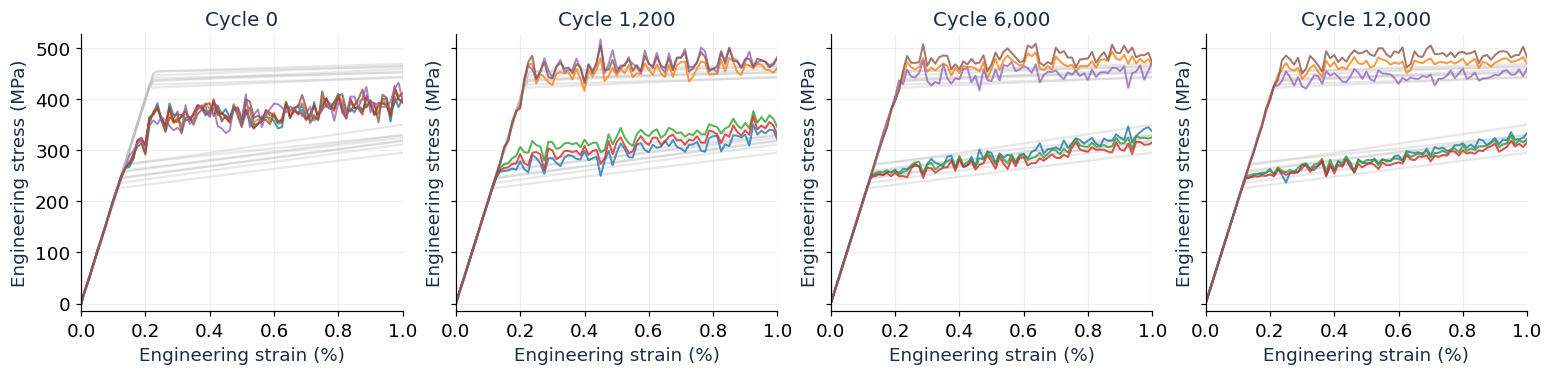

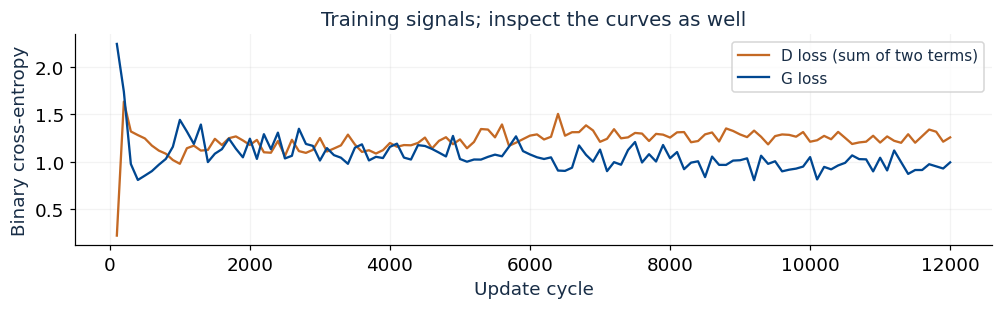

In [13]:
def show_training(result):
    items = list(result["snapshots"].items())
    fig, axes = plt.subplots(1, len(items), figsize=(14, 3.3), sharey=True,
                             squeeze=False, layout="constrained")
    all_values = np.concatenate([q.ravel() for _, q in items])
    lo, hi = min(-15, all_values.min()-10), max(525, all_values.max()+10)
    for ax, (cycle, curves) in zip(axes[0], items):
        ax.plot(100 * strain, check_curves[::25].T, color=".75", alpha=.35)
        ax.plot(100 * strain, curves[:6].T, lw=1.3, alpha=.8)
        curve_axes(ax, f"Cycle {cycle:,}")
        ax.set_ylim(lo, hi)
    plt.show()
    h = result["history"]
    if h.size:
        fig, ax = plt.subplots(figsize=(9, 2.7), layout="constrained")
        ax.plot(h[:, 0], h[:, 1], color=ORANGE, label="D loss (sum of two terms)")
        ax.plot(h[:, 0], h[:, 2], color=BLUE, label="G loss")
        ax.set(xlabel="Update cycle", ylabel="Binary cross-entropy", title="Training signals; inspect the curves as well")
        ax.legend(fontsize=10); ax.grid(alpha=.15); plt.show()

show_training(baseline)

## A6. Did G learn both the specimens and their variation?

We now draw **400 new curves** with fresh latent inputs and compare them with 400 held-aside reference curves. There is no one-to-one pairing. A mean-squared error between arbitrary generated and reference specimens would not measure whether the two populations match.

First inspect the complete curves and the region around yield. Then compare two simple descriptors:

- **Stress at 0.3% strain:** all reference specimens have yielded by this point, and their two families are separated here.
- **Late-loading slope:** fit a straight line over 0.6–1.0% strain. For a bilinear reference specimen this equals its post-yield tangent slope. For a generated curve it is only a summary of that segment.

These descriptors make family coverage visible. They are used **after training only** and do not replace the 81-value curves supplied to D.

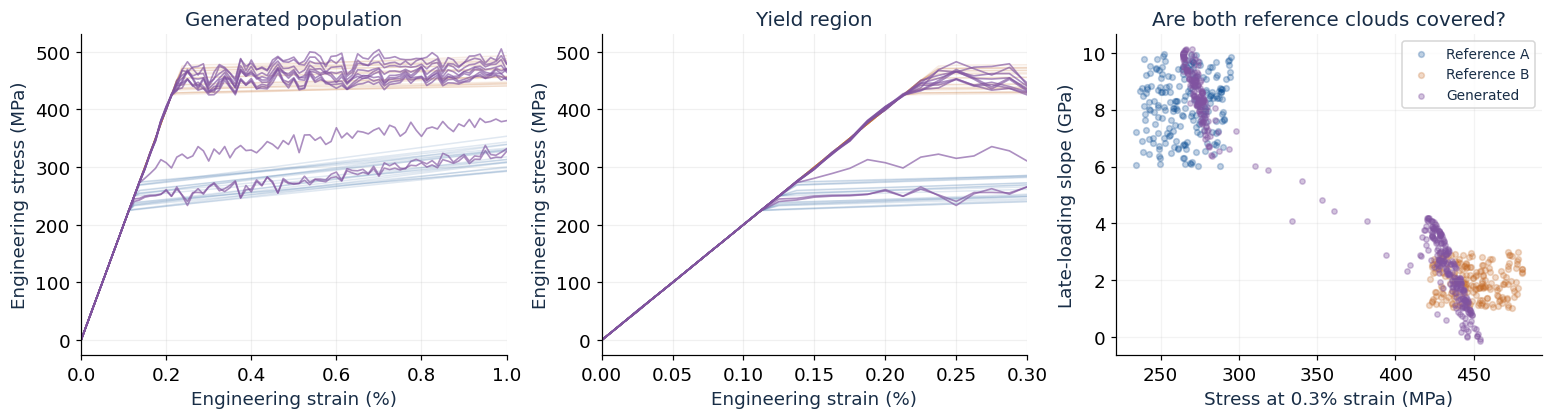

In [14]:
def fitted_slope(curves, mask):
    x = strain[mask].astype(float)
    x = x - x.mean()
    return np.asarray(curves)[:, mask] @ x / np.dot(x, x) / 1000  # GPa

def descriptors(curves):
    j = np.argmin(np.abs(strain - .003))
    return np.asarray(curves)[:, j], fitted_slope(curves, strain >= .006)

def compare_population(generated, title="Generated population"):
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.7), layout="constrained")
    for label, color, name in [(0, BLUE, "Reference A"), (1, ORANGE, "Reference B")]:
        ref = check_curves[check_family == label]
        for ax in axes[:2]:
            ax.plot(100 * strain, ref[:20].T, color=color, alpha=.12, lw=1)
        axes[2].scatter(*descriptors(ref), color=color, s=14, alpha=.25, label=name)
    for ax in axes[:2]:
        ax.plot(100 * strain, generated[:12].T, color=PURPLE, alpha=.65, lw=1.1)
    curve_axes(axes[0], title)
    curve_axes(axes[1], "Yield region", zoom=True)
    axes[2].scatter(*descriptors(generated), color=PURPLE, s=12, alpha=.35, label="Generated")
    axes[2].set(xlabel="Stress at 0.3% strain (MPa)", ylabel="Late-loading slope (GPa)",
                title="Are both reference clouds covered?")
    axes[2].legend(fontsize=9); axes[2].grid(alpha=.15)
    plt.show()

generated = generate(G, n=400, seed=123)
compare_population(generated)

### A mechanics check on the raw outputs

The table below checks the initial slope over 0–0.075% strain, the stress at zero strain, the late-loading slope, and local stress decreases. Our reference law has zero stress at zero strain, an initial slope of 200 GPa, and a nonnegative slope throughout loading.

We count stress drops larger than **2 MPa between adjacent grid points** to avoid letting negligible differences dominate the discussion. This is a chosen display tolerance, not a materials standard. Smaller oscillations can still matter.

No smoothing, clipping, or projection onto bilinear curves is applied. A sensible average slope can coexist with local wiggles. A curve can also look individually plausible while the generated population misses a family.

In [15]:
def audit(curves):
    elastic = fitted_slope(curves, strain <= .00075)
    late = descriptors(curves)[1]
    interval = lambda a: f"{np.quantile(a,.05):.1f} to {np.quantile(a,.95):.1f}"
    return [interval(elastic), interval(late),
            f"{np.median(np.abs(curves[:,0])):.2f}",
            f"{100*np.mean(np.any(np.diff(curves,axis=1) < -2,axis=1)):.1f}%"]

def show_audit(generated):
    names = ["Initial slope, central 90% (GPa)", "Late-loading slope, central 90% (GPa)",
             "Median absolute stress at zero strain (MPa)", "Curves with at least one >2 MPa local drop"]
    rows = ["| Check | Reference | Generated |", "|---|---:|---:|"]
    rows += [f"| {n} | {r} | {g} |" for n,r,g in zip(names,audit(check_curves),audit(generated))]
    display(Markdown("\n".join(rows)))

show_audit(generated)

| Check | Reference | Generated |
|---|---:|---:|
| Initial slope, central 90% (GPa) | 200.0 to 200.0 | 199.7 to 200.7 |
| Late-loading slope, central 90% (GPa) | 1.2 to 9.5 | 0.8 to 9.8 |
| Median absolute stress at zero strain (MPa) | 0.00 | 0.14 |
| Curves with at least one >2 MPa local drop | 0.0% | 100.0% |

### Quick discussion · a plausible curve is not enough

Do both clouds appear? Does each cloud have a comparable spread? Are curves between the clouds present? Do the physical checks agree with your first visual impression?

**Mode collapse** means many different latent inputs produce samples from only part of the reference distribution. It can occur between families or within a family. Missing modes, incorrect parameter variation and nonphysical curve shapes are different failure modes.

The next cell constructs a deliberately collapsed population from **only reference family A**. It contains individually valid curves for this model but fails to reproduce the full population. This is an illustration, **not output from a trained GAN**.

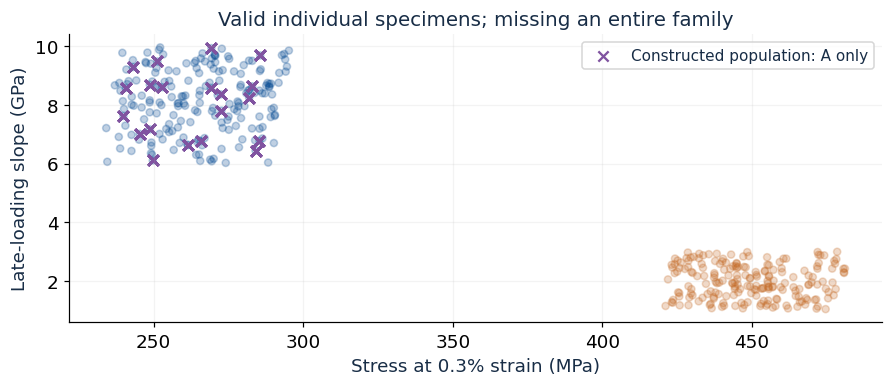

In [16]:
collapsed_example = np.repeat(check_curves[check_family == 0][:20], 20, axis=0)
ref_x, ref_y = descriptors(check_curves)
fake_x, fake_y = descriptors(collapsed_example)
fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
ax.scatter(ref_x, ref_y, c=np.where(check_family == 0, BLUE, ORANGE), alpha=.25, s=22)
ax.scatter(fake_x, fake_y, color=PURPLE, marker="x", s=45, label="Constructed population: A only")
ax.set(xlabel="Stress at 0.3% strain (MPa)", ylabel="Late-loading slope (GPa)",
        title="Valid individual specimens; missing an entire family")
ax.legend(fontsize=10); ax.grid(alpha=.15); plt.show()

## A7. Walk through latent space

The latent space is the plane of inputs $(z_1,z_2)$. Each point on this plane produces one complete curve. We can therefore colour the plane by a property of that curve.

**Left:** stress at 0.3% strain. **Right:** late-loading slope. The dashed circles have radii 1 and 2. Training draws from a two-dimensional normal distribution, so points near the centre are sampled more densely than distant points. A uniform grid is useful for inspection, but it does **not** reproduce the training sampling density.

These are maps of **G's output**, not encoded reference specimens. We have no encoder that could place a reference curve at a unique latent point. Nor should we assume $z_1$ means yield stress or $z_2$ means hardening.

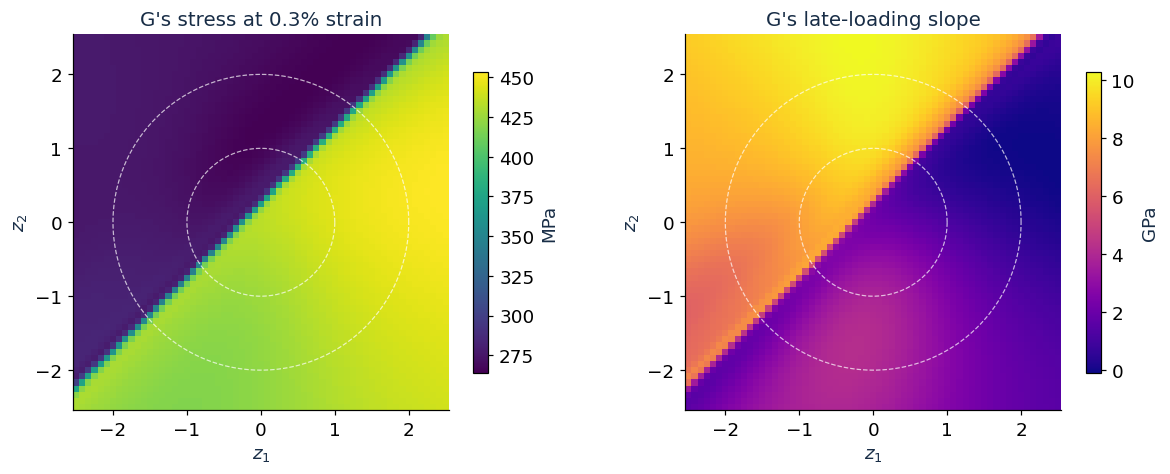

In [17]:
latent_axis = np.linspace(-2.5, 2.5, 61, dtype=np.float32)
zz1, zz2 = np.meshgrid(latent_axis, latent_axis)
latent_grid = np.column_stack([zz1.ravel(), zz2.ravel()])
latent_curves = generate(G, z=latent_grid)
latent_stress, latent_slope = descriptors(latent_curves)

def latent_background(ax, values, title, cmap="viridis"):
    im = ax.pcolormesh(zz1, zz2, values.reshape(zz1.shape), shading="auto", cmap=cmap)
    angle = np.linspace(0, 2*np.pi, 200)
    for radius in [1, 2]:
        ax.plot(radius*np.cos(angle), radius*np.sin(angle), "w--", lw=.8, alpha=.7)
    ax.set(xlabel="$z_1$", ylabel="$z_2$", title=title, aspect="equal")
    return im

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
im = latent_background(axes[0], latent_stress, "G's stress at 0.3% strain")
fig.colorbar(im, ax=axes[0], label="MPa", shrink=.8)
im = latent_background(axes[1], latent_slope, "G's late-loading slope", "plasma")
fig.colorbar(im, ax=axes[1], label="GPa", shrink=.8)
plt.show()

### Choose a point and see its specimen

Move one slider at a time. Find an A-like curve, a B-like curve, and a curve in between. The network weights stay fixed: **sampling a new specimen does not retrain G**.

If sliders do not display in your notebook viewer, edit `Z1` and `Z2` in the next cell and rerun it. That route gives exactly the same result. A static result is shown before the optional widget controls.

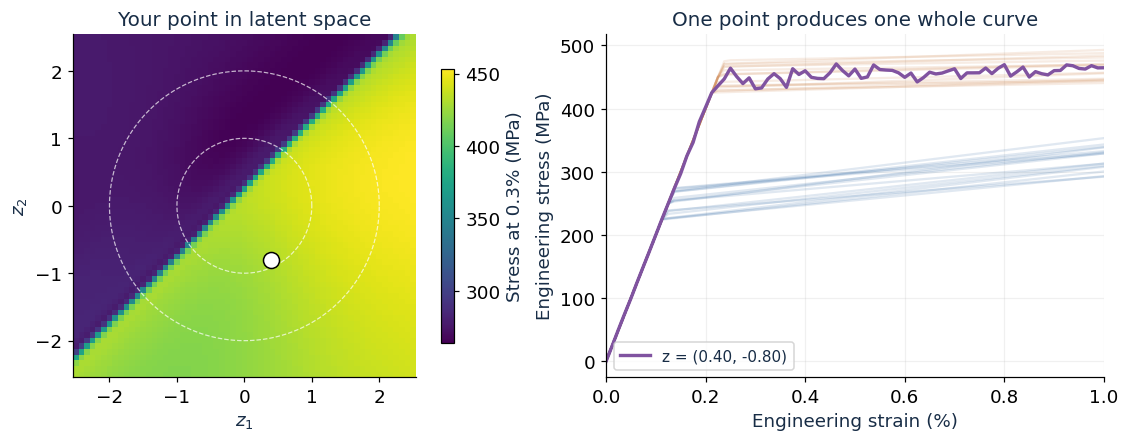

In [18]:
def explore_latent(z1, z2):
    curve = generate(G, z=[[z1, z2]])[0]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), layout="constrained")
    im = latent_background(axes[0], latent_stress, "Your point in latent space")
    axes[0].scatter([z1], [z2], color="white", edgecolor="black", s=110, zorder=4)
    fig.colorbar(im, ax=axes[0], label="Stress at 0.3% (MPa)", shrink=.8)
    for label, color in [(0, BLUE), (1, ORANGE)]:
        axes[1].plot(100*strain, check_curves[check_family == label][:15].T,
                      color=color, alpha=.12)
    axes[1].plot(100*strain, curve, color=PURPLE, lw=2.2, label=f"z = ({z1:.2f}, {z2:.2f})")
    curve_axes(axes[1], "One point produces one whole curve")
    axes[1].legend(fontsize=10)
    return fig

# YOUR LATENT COORDINATES. Edit these if you prefer cells to sliders.
Z1, Z2 = 0.4, -0.8
explore_latent(Z1, Z2)
plt.show()

In [19]:
# Optional controls: moving a slider only evaluates the already-trained generator.
slider = dict(min=-2.5, max=2.5, step=.1, continuous_update=False)
z1_slider = widgets.FloatSlider(value=Z1, description="z₁", **slider)
z2_slider = widgets.FloatSlider(value=Z2, description="z₂", **slider)
latent_image = widgets.Image(format="png", layout=widgets.Layout(max_width="100%"))

def update_latent_image(change=None):
    figure = explore_latent(z1_slider.value, z2_slider.value)
    buffer = BytesIO()
    figure.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    plt.close(figure)
    latent_image.value = buffer.getvalue()

z1_slider.observe(update_latent_image, names="value")
z2_slider.observe(update_latent_image, names="value")
update_latent_image()
display(widgets.VBox([widgets.HBox([z1_slider, z2_slider]), latent_image]))

### A path between two specimens

Choose two points from your exploration, then blend their **latent inputs**. We do not blend their stress values. The nonlinear G converts each intermediate input into a new curve.

**Predict:** if the endpoints belong near different families, must every curve along the path resemble a reference specimen? Is moving smoothly through latent space the same as remaining inside a populated family?

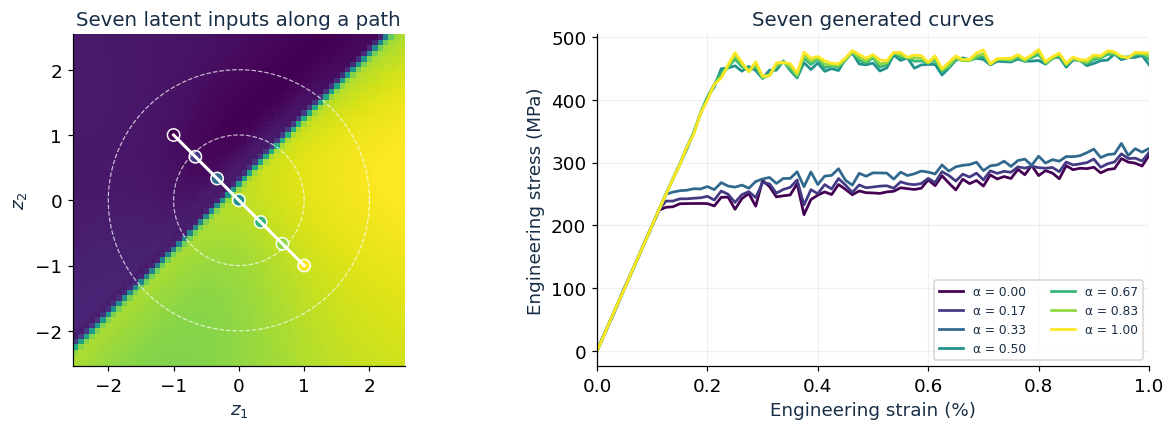

In [20]:
# Change these endpoints to points you found on the map.
Z_START = np.array([-1.0, 1.0])
Z_END = np.array([1.0, -1.0])
alpha = np.linspace(0, 1, 7)
path = (1-alpha[:,None])*Z_START + alpha[:,None]*Z_END
path_curves = generate(G, z=path)
colors = plt.cm.viridis(alpha)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
latent_background(axes[0], latent_stress, "Seven latent inputs along a path")
axes[0].plot(path[:,0], path[:,1], "w-", lw=2)
axes[0].scatter(path[:,0], path[:,1], c=colors, edgecolor="white", s=65)
for a, curve, color in zip(alpha, path_curves, colors):
    axes[1].plot(100*strain, curve, color=color, lw=1.8, label=f"α = {a:.2f}")
curve_axes(axes[1], "Seven generated curves")
axes[1].legend(fontsize=8, ncol=2); plt.show()

<details><summary><b>After discussing: continuity and the gap between families</b></summary>

Our MLP is continuous. Its outputs change continuously along a latent path, so a path between two separated families passes through intermediate outputs. The learned transition can be narrow, but continuity alone cannot guarantee that every generated curve resembles the reference population or satisfies mechanics. The axes can also mix several curve properties. Latent coordinates have no fixed physical meaning across independently trained models.

</details>

## A8. Exercise 2 · change the competition

Work with a neighbour. Change **only D's learning rate** using the multiplier below. Keep the data, initial seed, G learning rate and requested update cycles fixed.

1. **Predict:** with a faster D, will G learn better curves, miss a family, or change little? Explain your reasoning before running.
2. **Run:** try a multiplier of **5**. Another group can try **0.2**.
3. **Compare:** look at family coverage, variation and the physical checks. Do the losses tell the same story?
4. **Discuss:** would one successful or failed run justify a general claim? A second seed is an optional extension.

The baseline models remain available for the final activity. This cell starts the experiment from scratch, so rerunning it makes a controlled comparison instead of continuing previous training.

Cycle 1,200/12,000 · 1.1 s


Cycle 6,000/12,000 · 6.3 s


Cycle 12,000/12,000 · 13.7 s
completed · 12,000 cycles in 13.7 s


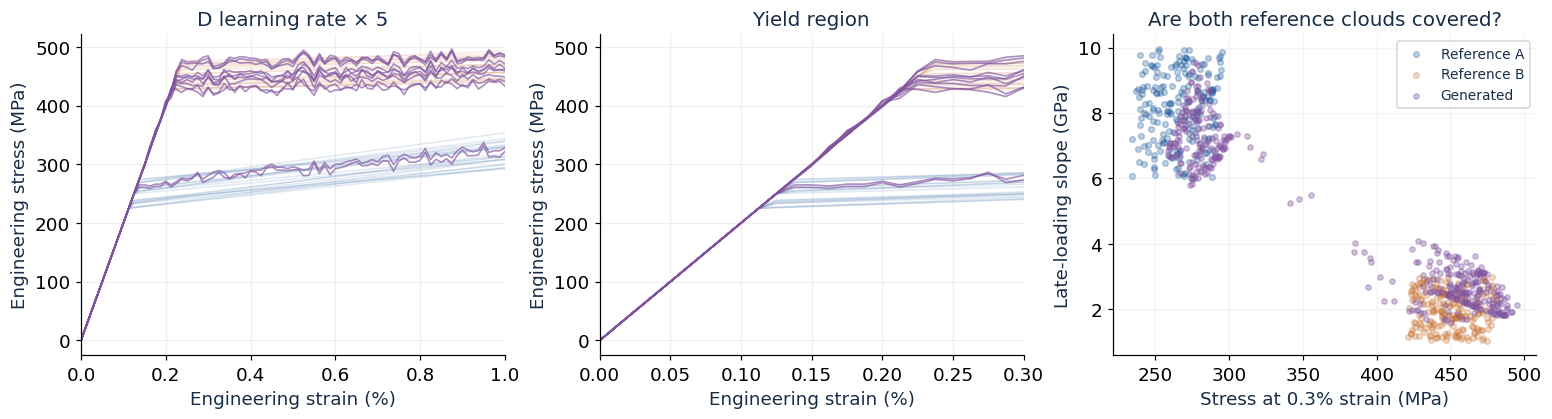

| Check | Reference | Generated |
|---|---:|---:|
| Initial slope, central 90% (GPa) | 200.0 to 200.0 | 199.6 to 200.3 |
| Late-loading slope, central 90% (GPa) | 1.2 to 9.5 | 1.9 to 8.4 |
| Median absolute stress at zero strain (MPa) | 0.00 | 0.11 |
| Curves with at least one >2 MPa local drop | 0.0% | 100.0% |

Baseline: 12,000 cycles. Experiment: 12,000 cycles.


In [21]:
# YOUR TRAINING KNOB: try 5.0 or 0.2.
D_LR_MULTIPLIER = 5.0
gan_experiment = train_gan(steps=BASELINE_STEPS, seed=MODEL_SEED,
                       g_lr=G_LEARNING_RATE,
                       d_lr=D_LEARNING_RATE * D_LR_MULTIPLIER)
experiment_curves = generate(gan_experiment["G"], n=400, seed=123)
compare_population(experiment_curves, title=f"D learning rate × {D_LR_MULTIPLIER:g}")
show_audit(experiment_curves)
print(f"Baseline: {baseline['cycles']:,} cycles. Experiment: {gan_experiment['cycles']:,} cycles.")
if baseline["cycles"] != gan_experiment["cycles"]:
    print("Time limits gave unequal training lengths. Account for that before attributing differences to the learning rate.")

<details><summary><b>After discussing: suggested interpretation</b></summary>

A stronger discriminator can offer useful feedback, but the two learners can also become poorly balanced. Increasing its learning rate need not improve family coverage or physical shape, and need not cause collapse every time. Compare the actual outputs. The same seed makes the comparison more controlled, but repeating several seeds is necessary to study a trend. If one run stops at the time budget, differences may also reflect unequal numbers of updates.

</details>

## A9. Your specimen: can you persuade the discriminator?

Choose your own $(z_1,z_2)$ using the **baseline** generator. The next cell makes your curve. Inspect its shape before revealing D's score in the following cell.

**Your challenge:** find a curve D calls “dataset-like”. Then decide independently whether it meets our mechanics checks. A high score and a reasonable curve shape answer different questions.

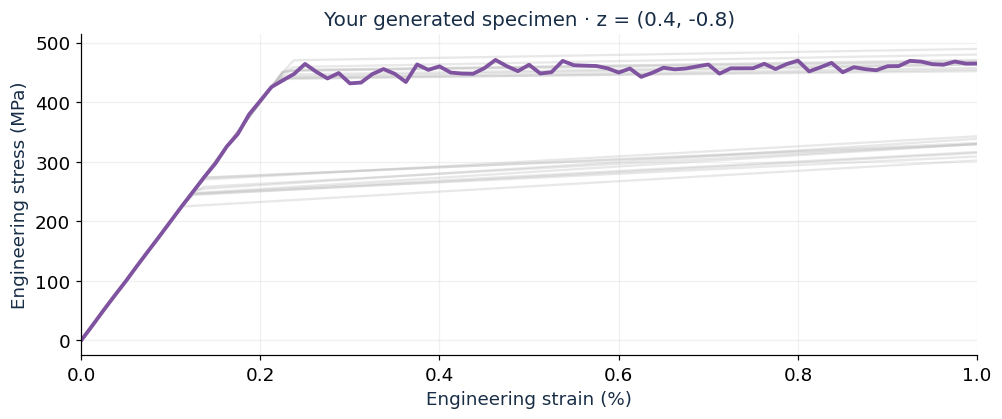

Known source: GENERATED. Predict D's verdict before running the next cell.


In [22]:
# MAKE YOUR OWN SPECIMEN. Rerun this cell and the verdict cell after changing z.
MY_Z1 = 0.4
MY_Z2 = -0.8
my_curve = generate(G, z=[[MY_Z1, MY_Z2]])[0]

fig, ax = plt.subplots(figsize=(9, 3.7), layout="constrained")
ax.plot(100*strain, check_curves[::20].T, color=".75", alpha=.35)
ax.plot(100*strain, my_curve, color=PURPLE, lw=2.5)
curve_axes(ax, f"Your generated specimen · z = ({MY_Z1:g}, {MY_Z2:g})")
plt.show()
print("Known source: GENERATED. Predict D's verdict before running the next cell.")

### Ask D to judge your curve

We use 0.5 as a **chosen classification threshold**. Above it, D guesses “dataset-like”; below it, D guesses “generated-like”. Scores near 0.5 indicate a weak preference and should not be overinterpreted.

Regardless of this guess, we know your curve's actual source: **G generated it**. If it fools D, its origin does not change. The score is not a calibrated probability that a specimen exists or that a material law is satisfied. If a GAN perfectly matches the reference distribution, an optimal D would give 0.5, so endlessly chasing a score near 1 is not the definition of a successful GAN.

D score: 0.383 · D's guess at threshold 0.5: generated-like
Actual source: generated by G. This score is not a physics certificate.


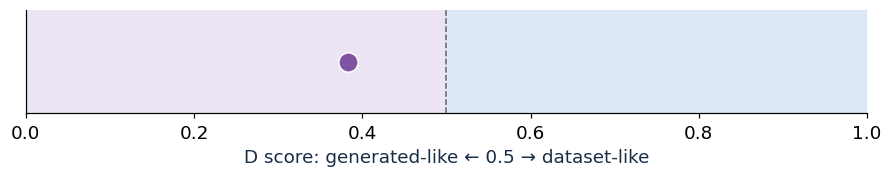

| Check | Reference | Generated |
|---|---:|---:|
| Initial slope, central 90% (GPa) | 200.0 to 200.0 | 200.3 to 200.3 |
| Late-loading slope, central 90% (GPa) | 1.2 to 9.5 | 3.3 to 3.3 |
| Median absolute stress at zero strain (MPa) | 0.00 | 0.22 |
| Curves with at least one >2 MPa local drop | 0.0% | 100.0% |

In [23]:
def discriminator_score(D, curves_mpa):
    values = np.atleast_2d(curves_mpa)
    with torch.no_grad():
        return torch.sigmoid(D(to_network(values))).cpu().numpy().ravel()

my_score = float(discriminator_score(D, my_curve)[0])
verdict = "dataset-like" if my_score >= .5 else "generated-like"
print(f"D score: {my_score:.3f} · D's guess at threshold 0.5: {verdict}")
print("Actual source: generated by G. This score is not a physics certificate.")
fig, ax = plt.subplots(figsize=(8, 1.5), layout="constrained")
ax.axvspan(0, .5, color="#ece4f2"); ax.axvspan(.5, 1, color="#dce9f5")
ax.axvline(.5, color=".4", ls="--", lw=1)
ax.scatter([my_score], [.5], s=160, color=PURPLE, edgecolor="white", zorder=3)
ax.set(xlim=(0,1), ylim=(0,1), yticks=[], xlabel="D score: generated-like ← 0.5 → dataset-like")
plt.show()
show_audit(my_curve[None,:])

### Check D against examples whose sources we know

Below, D scores 400 held-aside reference curves and 400 generated curves. Overlap shows why a score cannot reliably establish an individual curve's source. A threshold is a decision rule, not ground truth.

Try finding both a low-scoring reference curve and a high-scoring generated curve. If either is absent in this run, that observation is also useful: D's behaviour changes with training.

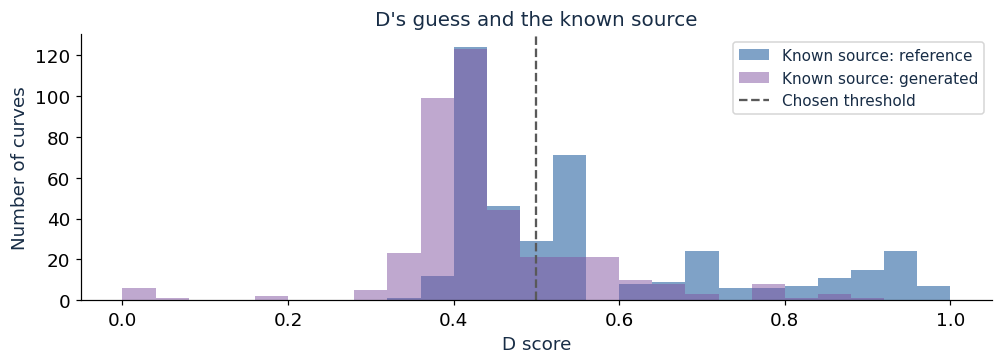

Held-aside reference curves called dataset-like: 50.2%
Generated curves called dataset-like: 21.5%


In [24]:
reference_scores = discriminator_score(D, check_curves)
generated_scores = discriminator_score(D, generated)
fig, ax = plt.subplots(figsize=(9, 3.2), layout="constrained")
bins = np.linspace(0, 1, 26)
ax.hist(reference_scores, bins=bins, alpha=.5, color=BLUE, label="Known source: reference")
ax.hist(generated_scores, bins=bins, alpha=.5, color=PURPLE, label="Known source: generated")
ax.axvline(.5, color=".35", ls="--", label="Chosen threshold")
ax.set(xlabel="D score", ylabel="Number of curves", title="D's guess and the known source")
ax.legend(fontsize=10); plt.show()
print(f"Held-aside reference curves called dataset-like: {100*np.mean(reference_scores >= .5):.1f}%")
print(f"Generated curves called dataset-like: {100*np.mean(generated_scores >= .5):.1f}%")

## A10. What should we take away?

- **Learning:** D learns a source distinction. G learns from gradients through D. Their updates change different weights.
- **Sampling:** changing z makes a new curve using the same trained G. A latent map helps us inspect that relationship.
- **Coverage:** matching a few attractive curves is insufficient. We need the variation within both families.
- **Mechanics:** learning from physically constructed examples does not automatically enforce the underlying law. Our audits never enter the training loss.
- **Judgement:** D's score measures its learned preference. The known source and physical checks supply separate evidence.

We already know how to sample this bilinear model directly, so a GAN is not needed to make this particular dataset. Its value here is as a small, inspectable example of adversarial learning. For a genuinely unknown population, the quality and coverage of the reference data would become central questions.

---

## From the GAN to the PINN · keep the runtime running

The GAN learned what a collection of examples looks like. We checked its mechanics **after training**. In the next case, a physical equation will help define the training objective itself.

| What changes? | Part A · GAN | Part B · PINN |
|---|---|---|
| Input | Random latent coordinates | Physical position and time $(x,y,t)$ |
| Output of one evaluation | One complete stress–strain curve | One pressure value at the query point |
| Training signal | Competition with a discriminator | Equation, wall and initial-condition mismatches; later sensor data |
| Our check | Population coverage and mechanics audits | Reference pressure and physics checks at new points |

Continue with the next cell. The shared libraries stay loaded, and all GAN results remain available. The acoustic model is created from scratch with its own seed. Optional GAN exercises are collected at the end so the live session flows directly into the cavity problem.

<a id="part-b"></a>

# Part B · PINNs: can a neural network listen to physics?
Imagine a sealed cavity. We create a small pressure disturbance and release it. The pressure starts oscillating; waves reflect from the walls. **Can we predict the pressure everywhere without showing a neural network the interior pressure history?**

We will build a **physics-informed neural network (PINN)**, inspect what it gets right, and deliberately remove one piece of its physics. Finally, two virtual microphones will help us identify an unknown wave speed.

**Second half of the session · about 40 minutes.** We continue in the same runtime.

## Part B · route through the next 40 minutes

| Activity | Minutes |
|---|---:|
| Explore the cavity physics with sliders | 6 |
| Decide where to check the equations | 3 |
| Meet the network and automatic differentiation | 5 |
| Build and balance four loss terms | 6 |
| Train, inspect maps and validate | 8 |
| Experiment: remove the wall penalty | 4 |
| Inverse problem: listen with two sensors | 6 |
| Takeaways and bridge to the lecture | 2 |

## B1. Physics first: pressure in a rigid cavity

Our two-dimensional cavity has width 2 and height 1. All quantities below are **nondimensional**: positions, times, pressure and wave speed have been divided by reference scales. A speed of $c=1$ is not a speed of 1 m/s.

We model small acoustic disturbances in a homogeneous fluid at rest, with constant wave speed. We neglect viscosity, damping and mean flow, and assume no variation in the third direction. The plotted $p$ is a **pressure fluctuation about equilibrium**. Negative values are rarefactions; they do not mean negative absolute pressure.

A rigid wall cannot move normally to its surface. In this acoustic model the resulting condition is **zero normal pressure gradient**, $\partial p/\partial n=0$. Pressure at the wall can still oscillate and can be large.

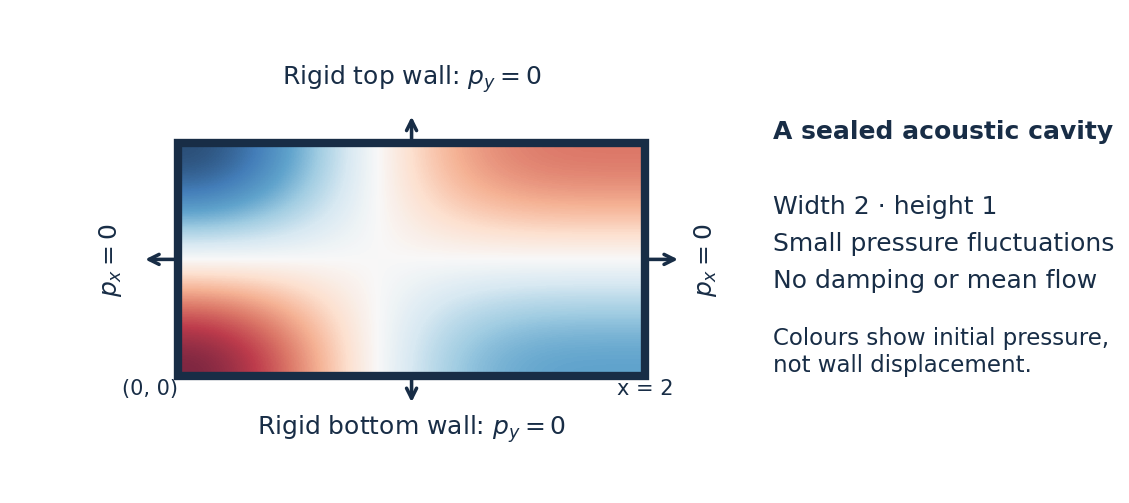

### The equation and the initial “push”

The wave equation links time curvature to spatial curvature:

$$\underbrace{p_{tt}}_{\text{curvature in time}}
= c^2\underbrace{(p_{xx}+p_{yy})}_{\text{curvature in space}},
\qquad 0\leq x\leq2,\;0\leq y\leq1,\;0\leq t\leq0.6.$$

A nonuniform pressure field can change even without an external source. To select a particular motion, a second-order time equation needs **two initial conditions**:

$$p(x,y,0)=\underbrace{\cos(\pi x/2)\cos(\pi y)}_{\text{pattern 1}}
+\underbrace{0.25\cos(\pi x)\cos(\pi y)}_{\text{pattern 2}},\qquad p_t(x,y,0)=0.$$

These are two standing-wave patterns compatible with the rigid walls. Each pattern keeps its spatial shape while its amplitude oscillates; they oscillate at different frequencies. Their sum can change shape. The second starts with one quarter of the modal amplitude of the first.

Here “starts from rest” means **the pressure initially has zero rate of change**. $p_t$ is a pressure rate, not the fluid particle velocity. The pressure need not stay still: $p_{tt}$ is generally nonzero.

> **Predict, before running:** if we double $c$, will the initial pressure pattern change? Will it oscillate faster or slower? Must the pressure vanish at a rigid wall?

### Set the acoustic problem's scales and seed

The libraries are already loaded. We only define the cavity time interval, the PINN seed and a numerical loss scale. This cell does not clear or replace the trained GANs.

In [25]:
# Part B settings — shared libraries come from the setup cell at the top.
SEED, TMAX = 20261013, 0.6
OMEGA_REF = math.pi * math.sqrt(1.25)  # Fixed numerical scale, explained in section B4.
print("Acoustic cavity ready. The GAN results and sliders remain available.")

Acoustic cavity ready. The GAN results and sliders remain available.


### A reference solution we can inspect

This special initial pattern has an analytical solution:

$$p_{\rm ref}(x,y,t)=\cos(\pi x/2)\cos(\pi y)\cos(c\pi\sqrt{5/4}\,t)
+0.25\cos(\pi x)\cos(\pi y)\cos(c\pi\sqrt{2}\,t).$$

At $t=0$ both time factors are 1 and their first derivatives are zero. The normal derivatives at the walls are also zero. Each mode satisfies the wave equation because its squared frequency equals $c^2$ times its squared spatial wavenumber.

**We keep this answer separate from forward training.** The forward PINN sees the prescribed initial pressure and the equations. We use the complete solution to understand the physics, check the result, and later create synthetic sensor measurements.

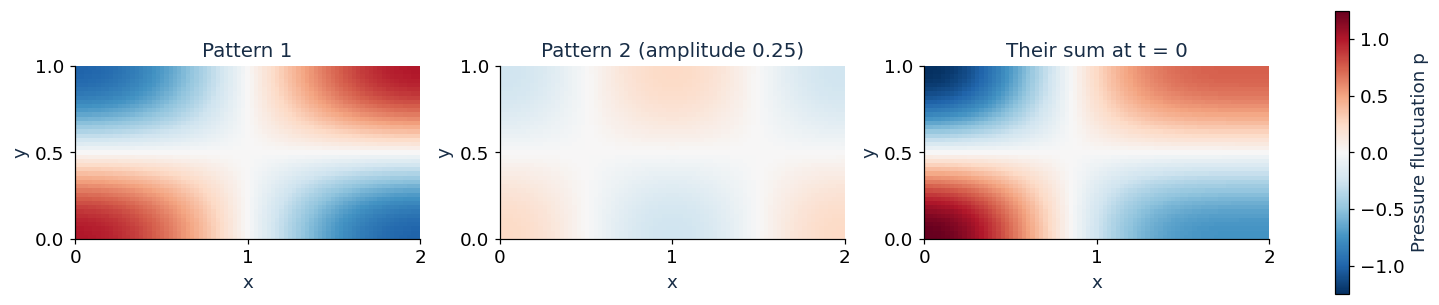

In [26]:
def initial_pressure(q):
    x, y = q[:, 0:1], q[:, 1:2]
    return torch.cos(math.pi*x/2)*torch.cos(math.pi*y) + .25*torch.cos(math.pi*x)*torch.cos(math.pi*y)

def reference_pressure(q, c=1.0):
    x, y, t = q[:, 0:1], q[:, 1:2], q[:, 2:3]
    mode1 = torch.cos(math.pi*x/2)*torch.cos(math.pi*y)
    mode2 = .25*torch.cos(math.pi*x)*torch.cos(math.pi*y)
    return (mode1*torch.cos(c*math.pi*math.sqrt(1.25)*t)
            + mode2*torch.cos(c*math.pi*math.sqrt(2.0)*t))

# A plotting grid is just a collection of coordinates, not a training dataset.
X, Y = np.meshgrid(np.linspace(0, 2, 81), np.linspace(0, 1, 41))
PRESSURE_LIMIT = 1.25  # A common scale: |mode 1| + |mode 2| <= 1.25.
PROBES = [(0.3, 0.25), (1.4, 0.7)]

def map_coordinates(t):
    return torch.tensor(np.column_stack([X.ravel(), Y.ravel(), np.full(X.size, t)]), dtype=torch.float32)

def trace_coordinates(x, y, times):
    return torch.tensor(np.column_stack([np.full(len(times), x), np.full(len(times), y), times]), dtype=torch.float32)

def pressure_map(ax, values, title, limit=PRESSURE_LIMIT):
    im = ax.imshow(np.asarray(values).reshape(X.shape), extent=(0, 2, 0, 1), origin="lower",
                   vmin=-limit, vmax=limit, cmap="RdBu_r", aspect="equal")
    ax.set(xlabel="x", ylabel="y", title=title, xticks=[0, 1, 2], yticks=[0, .5, 1])
    return im

fig, axs = plt.subplots(1, 3, figsize=(13, 3.3), layout="constrained")
mode1 = np.cos(np.pi*X/2)*np.cos(np.pi*Y)
mode2 = .25*np.cos(np.pi*X)*np.cos(np.pi*Y)
for ax, values, title in zip(axs, [mode1, mode2, mode1+mode2], ["Pattern 1", "Pattern 2 (amplitude 0.25)", "Their sum at t = 0"]):
    im = pressure_map(ax, values, title)
fig.colorbar(im, ax=axs, label="Pressure fluctuation p", shrink=.8)
plt.show()

### Move time forward; then change wave speed

The two points are virtual microphones. The pressure map and their time traces show the same solution in different ways. All pressure maps use the same colour scale, including later PINN predictions.

**Try:** start at $t=0$, advance time, then increase the demonstration speed. The initial pattern stays the same. Faster oscillation changes the time history. This physics panel does not retrain anything or change the later $c=1$ forward problem.

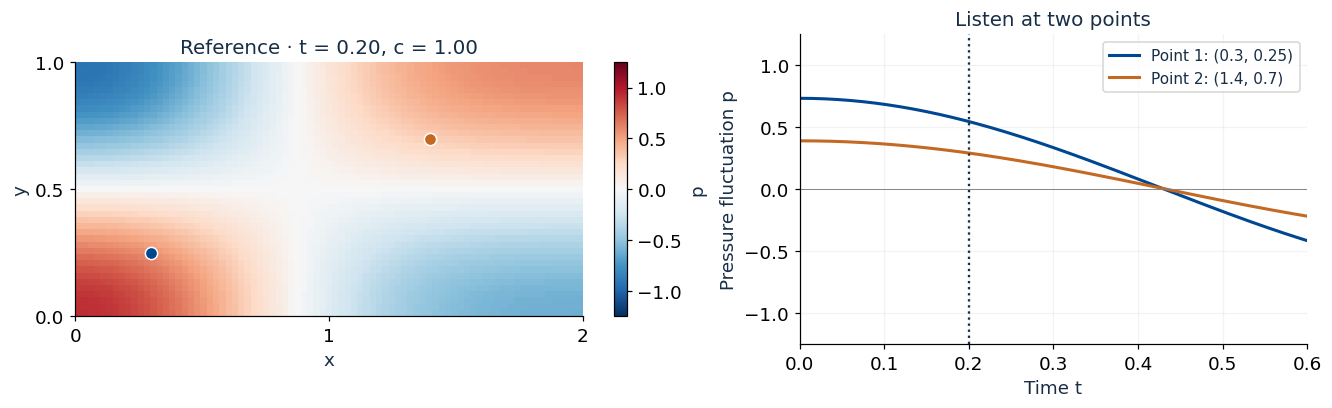

In [27]:
def reference_panel(t=.2, c_demo=1.):
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), layout="constrained")
    im = pressure_map(axs[0], reference_pressure(map_coordinates(t), c_demo).numpy(), f"Reference · t = {t:.2f}, c = {c_demo:.2f}")
    fig.colorbar(im, ax=axs[0], label="p", shrink=.82)
    times = np.linspace(0, TMAX, 161)
    for i, ((x, y), colour) in enumerate(zip(PROBES, [BLUE, ORANGE]), 1):
        axs[0].plot(x, y, "o", color=colour, mec="white", ms=8)
        values = reference_pressure(trace_coordinates(x, y, times), c_demo).numpy().ravel()
        axs[1].plot(times, values, color=colour, lw=2, label=f"Point {i}: ({x}, {y})")
    axs[1].axvline(t, color=INK, ls=":")
    axs[1].axhline(0, color="grey", lw=.6)
    axs[1].set(xlabel="Time t", ylabel="Pressure fluctuation p", title="Listen at two points", xlim=(0,TMAX), ylim=(-1.25,1.25))
    axs[1].legend(fontsize=10); axs[1].grid(alpha=.15)
    return fig

# Editable fallback if widgets are unavailable. Change these numbers and rerun.
DEMO_TIME, DEMO_SPEED = .2, 1.
reference_panel(DEMO_TIME, DEMO_SPEED)
plt.show()

In [28]:
# These widgets update a figure; they never start training.
def show_png(image_widget, figure):
    buffer = BytesIO()
    figure.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    plt.close(figure)
    image_widget.value = buffer.getvalue()

physics_time = widgets.FloatSlider(value=.2, min=0, max=TMAX, step=.01, description="Time t", continuous_update=False)
physics_speed = widgets.FloatSlider(value=1., min=.5, max=1.5, step=.05, description="Demo c", continuous_update=False)
physics_image = widgets.Image(format="png", layout=widgets.Layout(max_width="100%"))
def update_physics(change=None):
    show_png(physics_image, reference_panel(physics_time.value, physics_speed.value))
for control in [physics_time, physics_speed]:
    control.observe(update_physics, names="value")
update_physics()
display(widgets.VBox([widgets.HBox([physics_time, physics_speed]), physics_image]))

<details><summary>Discuss after exploring</summary>

Changing $c$ changes the temporal frequencies, not the prescribed initial pattern. A rigid wall means zero **normal derivative**, not zero pressure. The common nodal line $y=0.5$ has zero pressure for both modes at every time; a microphone there would tell us little about their frequencies.

</details>

## B2. What will the network learn from?

For the **forward problem**, $c=1$ is known. We want the field $p(x,y,t)$.

A PINN is a neural network whose training loss includes equations and conditions that its output should satisfy. It combines a flexible function with a physics-based training signal. Here there are **no interior pressure labels** and no simulator-generated training trajectories.

| Where we evaluate the network | What we ask it to satisfy | Points in the default run |
|---|---|---:|
| Inside the cavity, across time | Wave equation | 512 |
| On each wall, across time | Zero normal pressure gradient | 64 per wall |
| Throughout the cavity at $t=0$ | Prescribed initial pressure | 144 |
| The same initial coordinates | Zero initial pressure rate | 144 |

A **collocation point** is a coordinate where we check an equation. It is not a measured pressure. We use a reproducible, space-filling Sobol sequence to spread points through the domain. These fixed points are reused during training; validation will check other points.

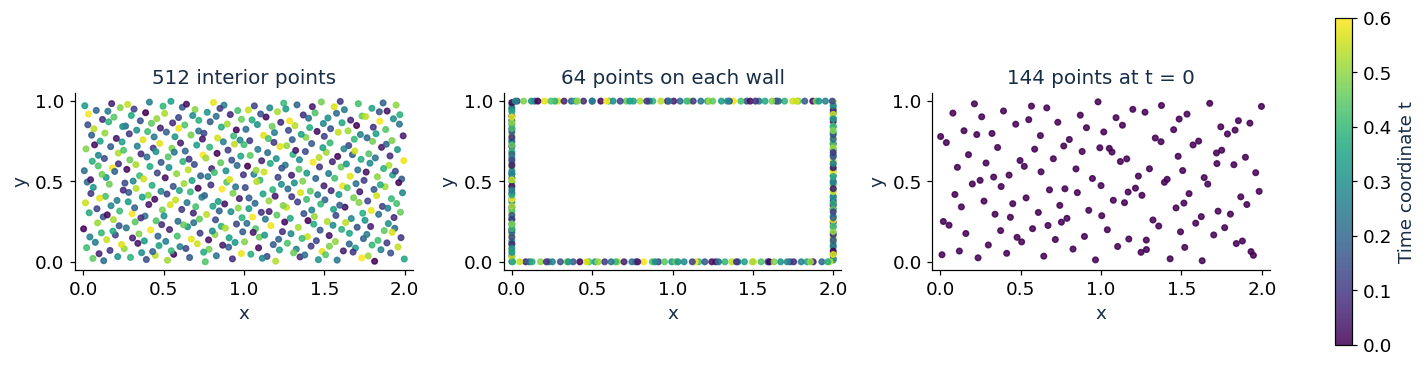

These are spatial projections: each interior/wall dot also has a time coordinate (colour).
Initial pressure and initial rate use the same t = 0 points, with separate loss terms.


In [29]:
def sample_points(n_interior=512, n_per_wall=64, n_initial=144, seed=SEED):
    sampler = torch.quasirandom.SobolEngine(3, scramble=True, seed=seed)
    scale = torch.tensor([2.0, 1.0, TMAX])
    interior = sampler.draw(n_interior)*scale
    walls = sampler.draw(4*n_per_wall)*scale
    walls[:n_per_wall, 0] = 0
    walls[n_per_wall:2*n_per_wall, 0] = 2
    walls[2*n_per_wall:3*n_per_wall, 1] = 0
    walls[3*n_per_wall:, 1] = 1
    normals = torch.repeat_interleave(torch.tensor([[-1.,0.],[1.,0.],[0.,-1.],[0.,1.]]), n_per_wall, dim=0)
    initial = sampler.draw(n_initial)*torch.tensor([2.0, 1.0, 0.0])
    return dict(interior=interior, walls=walls, normals=normals, initial=initial,
                initial_target=initial_pressure(initial).detach())

points = sample_points()
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for ax, name, title in zip(axs, ["interior", "walls", "initial"],
        ["512 interior points", "64 points on each wall", "144 points at t = 0"]):
    q = points[name].numpy()
    scatter = ax.scatter(q[:,0], q[:,1], c=q[:,2], vmin=0, vmax=TMAX, cmap="viridis", s=13, alpha=.85)
    ax.set(xlim=(-.05,2.05), ylim=(-.05,1.05), xlabel="x", ylabel="y", title=title, aspect="equal")
fig.colorbar(scatter, ax=axs, label="Time coordinate t", shrink=.8)
plt.show()
print("These are spatial projections: each interior/wall dot also has a time coordinate (colour).")
print("Initial pressure and initial rate use the same t = 0 points, with separate loss terms.")

> **Quick question:** if we double the interior point count, do we need to run twice as many acoustic simulations to obtain labels?

<details><summary>Discuss after answering</summary>

No. We evaluate derivatives of our network at more coordinates. This costs computation, but needs no additional interior pressure labels. More points can help cover the domain; they do not automatically fix optimisation or poor loss balance.

</details>

## B3. One coordinate in, one pressure out

The network receives **three inputs $(x,y,t)$ and returns one scalar $p_\theta(x,y,t)$**. The symbol $\theta$ stands for all its weights and biases. To make a pressure map, we evaluate this same function at many coordinates. It does not output an entire grid from one coordinate.

The GAN generator produced a whole curve from random latent numbers. Here the input is a **physical location and time**, and one network represents one field. We use three hidden layers of 32 neurons with smooth `tanh` activations.

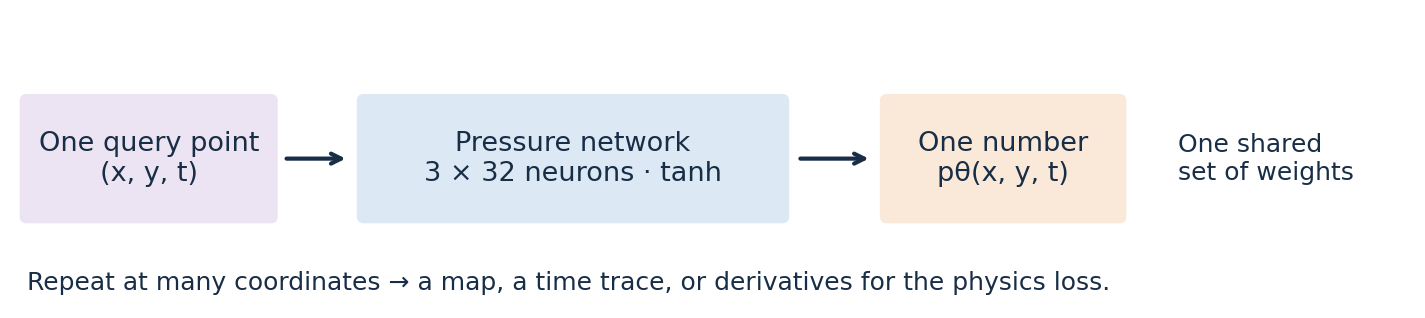

In [30]:
class PressureNet(nn.Module):
    def __init__(self, width=32):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(3,width), nn.Tanh(),
            nn.Linear(width,width), nn.Tanh(), nn.Linear(width,width), nn.Tanh(), nn.Linear(width,1))
    def forward(self, q):
        scaled_q = q*q.new_tensor([1.0, 2.0, 2.0/TMAX]) - 1
        return self.layers(scaled_q)

torch.manual_seed(SEED)
demo_net = PressureNet()
query = torch.tensor([[.3, .25, .2], [1.4, .7, .4]])
print(f"Trainable weights and biases: {sum(p.numel() for p in demo_net.parameters()):,}")
print("Query shape:", tuple(query.shape), "→ prediction shape:", tuple(demo_net(query).shape))
print("These first predictions are untrained; they have no physical meaning yet.")

Trainable weights and biases: 2,273
Query shape: (2, 3) → prediction shape: (2, 1)
These first predictions are untrained; they have no physical meaning yet.


### Automatic differentiation: asking for slopes and curvature

Before differentiating a network, try a function whose answer we know:

$$f(x,y,t)=x^2+2y^2+3t^2,\qquad (f_x,f_y,f_t)=(2x,4y,6t),\qquad(f_{xx},f_{yy},f_{tt})=(2,4,6).$$

PyTorch follows the operations that built the output and applies the chain rule. It does not estimate derivatives by moving a point a small distance.

`requires_grad_(True)` asks PyTorch to track input derivatives. `create_graph=True` keeps the derivative calculation differentiable: we need to differentiate it again for second derivatives and then train through the resulting physics loss.

In [31]:
def gradient(output, inputs):
    return torch.autograd.grad(output, inputs, grad_outputs=torch.ones_like(output),
                               create_graph=True)[0]

q = torch.tensor([[.4, .2, .3]], requires_grad=True)
f = q[:,0:1]**2 + 2*q[:,1:2]**2 + 3*q[:,2:3]**2
first = gradient(f, q)
f_xx = gradient(first[:,0:1], q)[:,0:1]
f_yy = gradient(first[:,1:2], q)[:,1:2]
f_tt = gradient(first[:,2:3], q)[:,2:3]
print("First derivatives [f_x, f_y, f_t]:", first.detach().numpy().round(3))
print("Second derivatives [f_xx, f_yy, f_tt]:", [float(v.detach()) for v in [f_xx, f_yy, f_tt]])
print("Wave residual for c = 1:", float((f_tt-f_xx-f_yy).detach()))

First derivatives [f_x, f_y, f_t]: [[0.8 0.8 1.8]]
Second derivatives [f_xx, f_yy, f_tt]: [2.0, 4.0, 6.0]
Wave residual for c = 1: 0.0


The polynomial even has zero wave residual for $c=1$, but it does not satisfy our wall or initial conditions. **An equation alone does not select the desired solution.**

For a batch, `grad_outputs=ones_like(...)` differentiates the sum of outputs. Because each row of our MLP is evaluated independently, the resulting row is the derivative at that point. We do not use layers that mix samples.

Two different derivatives appear in a PINN:

| Derivative | Purpose |
|---|---|
| $\partial p_\theta/\partial x$, $\partial^2 p_\theta/\partial t^2$, etc. | Evaluate the physics of the predicted field |
| $\partial\mathcal L/\partial\theta$ | Change the weights to reduce the loss |

We normalise the input coordinates **inside** the network's computation graph. The chain rule therefore returns derivatives with respect to the original nondimensional coordinates. `tanh` is smooth; a basic ReLU network is piecewise linear, with zero second derivatives away from its kinks, so it is a poor choice for this formulation of a second-order PDE.

In [32]:
def wave_residual(net, q, c):
    p = net(q)
    first = gradient(p, q)
    p_xx = gradient(first[:,0:1], q)[:,0:1]
    p_yy = gradient(first[:,1:2], q)[:,1:2]
    p_tt = gradient(first[:,2:3], q)[:,2:3]
    return p_tt - c**2*(p_xx + p_yy)

q_check = points["interior"][:5].clone().requires_grad_(True)
print("Five wave residuals of the untrained network:")
print(wave_residual(demo_net, q_check, c=1.).detach().numpy().ravel().round(3))

Five wave residuals of the untrained network:
[ 0.216  0.176  0.215 -0.078 -0.042]


## B4. Four promises, four loss terms

Let $\langle\cdot\rangle$ mean an average over the relevant sample points. The residual is $r=p_{tt}-c^2(p_{xx}+p_{yy})$.

| Term | Squared mismatch, averaged at the right points | What a small value asks for |
|---|---|---|
| PDE | $\mathcal L_f=\langle(r/\Omega_0^2)^2\rangle$ | Wave-like evolution |
| Wall | $\mathcal L_b=\langle((\nabla p\cdot\mathbf n)/\pi)^2\rangle$ | Rigid-wall reflection |
| Initial pressure | $\mathcal L_p=\langle(p(x,y,0)-p_0(x,y))^2\rangle$ | The specified initial disturbance |
| Initial rate | $\mathcal L_v=\langle(p_t(x,y,0)/\Omega_0)^2\rangle$ | Zero initial pressure rate |

We use fixed numerical scales $\Omega_0=\pi\sqrt{5/4}$ and $\pi$ so raw derivative magnitudes do not dominate just because differentiation introduces wavenumber factors. These scales only condition the objective. They stay fixed when we later learn $c$; they do not constrain its value.

The total forward loss is

$$\mathcal L=\lambda_f\mathcal L_f+\lambda_b\mathcal L_b+\lambda_p\mathcal L_p+\lambda_v\mathcal L_v.$$

Default weights are $(1,1,10,10)$. These are practical training choices, not physical constants. A larger weight makes the optimiser pay more attention to that mismatch. We will plot **each component**, because one total can hide a neglected objective. The name “initial velocity loss” sometimes appears in PINN code; here it means pressure rate $p_t$, not particle velocity.

In [33]:
BASE_WEIGHTS = dict(pde=1., wall=1., initial_pressure=10., initial_rate=10., data=20.)
# The data term is zero in the forward problem; it is used only in section B7.

def loss_terms(net, points, c=1.0, observations=None):
    # Fresh coordinate leaves avoid accumulating input gradients between updates.
    qf = points['interior'].detach().clone().requires_grad_(True)
    qb = points['walls'].detach().clone().requires_grad_(True)
    qi = points['initial'].detach().clone().requires_grad_(True)
    residual = wave_residual(net, qf, c)/OMEGA_REF**2
    wall_gradient = gradient(net(qb), qb)[:,:2]
    normal_gradient = (wall_gradient*points['normals']).sum(dim=1)/math.pi
    p_initial = net(qi)
    p_t_initial = gradient(p_initial, qi)[:,2:3]/OMEGA_REF
    terms = dict(pde=residual.square().mean(), wall=normal_gradient.square().mean(),
                 initial_pressure=(p_initial-points['initial_target']).square().mean(),
                 initial_rate=p_t_initial.square().mean())
    terms['data'] = (net(observations['q'])-observations['p']).square().mean() if observations is not None else p_initial.new_tensor(0.)
    return terms

terms = loss_terms(demo_net, points, c=1.)
weighted_loss = sum(BASE_WEIGHTS[name]*value for name, value in terms.items())
demo_net.zero_grad(set_to_none=True)
weighted_loss.backward()  # Now differentiate the loss with respect to the weights.
for name, value in terms.items():
    if name != "data": print(f"{name:18s}: {float(value.detach()):.4f}")
print(f"Norm of the first layer's weight gradient: {demo_net.layers[0].weight.grad.norm():.3f}")
print("The optimiser can use these weight gradients to improve the next prediction.")

pde               : 0.0002
wall              : 0.0006
initial_pressure  : 0.3703
initial_rate      : 0.0063
Norm of the first layer's weight gradient: 0.898
The optimiser can use these weight gradients to improve the next prediction.


### Stop and predict: could silence win?

**“Would $p=0$ satisfy the PDE and the rigid-wall conditions?”**

Discuss with your neighbour before running. Then identify which one of the four terms prevents this solution.

In [34]:
# For p = 0, every space/time derivative is zero. Only the prescribed pressure disagrees.
zero_field_losses = dict(pde=0., wall=0., initial_pressure=float(points["initial_target"].square().mean()), initial_rate=0.)
for name, value in zero_field_losses.items():
    print(f"{name:18s}: {value:.4f}")

pde               : 0.0000
wall              : 0.0000
initial_pressure  : 0.2707
initial_rate      : 0.0000


<details><summary>Discuss after answering</summary>

Silence satisfies the PDE, the walls and zero initial pressure rate. It fails the nonzero initial pressure. If we remove that term, the zero field is an admissible zero-loss solution. The optimiser may find another low-loss field instead, but it no longer has a reason to reproduce our intended disturbance.

</details>

### How we optimise (provided helper)

Every update evaluates all four sets of conditions and changes the **same network weights**. There is no adversarial opponent or alternating discriminator step.

We first use **Adam** for 1,800 updates, then **L-BFGS** for up to 250 refinement iterations on the same fixed point sets. L-BFGS uses curvature information and may evaluate the loss several times during one iteration. That is why our history plots use elapsed seconds rather than treating the two optimisers' steps as equivalent.

The helper below also supports the inverse problem later. Focus on `loss.backward()` and `optimizer.step()`: derivatives of the physics loss flow all the way back to the weights. Each call starts a **new** network with a reproducible seed. Re-running a training cell starts over.

A **110-second training budget** stops a slow run and clearly labels it partial. A partial run can be inspected, but its quality is not assumed to match a completed run. This guard is checked during optimisation and is not a hard operating-system deadline; plotting and setup add a small overhead.

In [35]:
def train_pinn(inverse=False, observations=None, seed=SEED, weights=None,
               n_interior=512, n_per_wall=64, n_initial=144,
               adam_steps=1800, refine_rounds=10, c_start=.7, max_seconds=110):
    if inverse and observations is None:
        raise ValueError('The inverse problem needs sensor measurements.')
    torch.manual_seed(seed)
    net = PressureNet()  # Always a fresh network, also for the inverse problem.
    points = sample_points(n_interior, n_per_wall, n_initial, seed=SEED)
    w = BASE_WEIGHTS.copy()
    if weights is not None: w.update(weights)
    if not inverse and observations is not None:
        raise ValueError('This forward exercise uses no sensor targets.')
    log_c = nn.Parameter(torch.tensor(math.log(c_start))) if inverse else None
    parameters = list(net.parameters()) + ([log_c] if inverse else [])
    speed = lambda: log_c.exp() if inverse else 1.0
    objective = lambda: loss_terms(net, points, speed(), observations)
    total = lambda terms: sum(w[name]*value for name,value in terms.items())
    start = time.perf_counter()
    history, stopped, adam_done, rounds_done = [], False, 0, 0
    def record(stage, step):
        terms = objective()
        history.append(dict(stage=stage, step=step, seconds=time.perf_counter()-start,
            c=float(torch.as_tensor(speed()).detach()), **{k:float(v.detach()) for k,v in terms.items()}))
    record('initial',0)
    adam = torch.optim.Adam(parameters, lr=.001)
    for step in range(1,adam_steps+1):
        if step % 10 == 1 and time.perf_counter()-start >= max_seconds:
            stopped = True; break
        adam.zero_grad(set_to_none=True)
        loss = total(objective()); loss.backward(); adam.step()
        adam_done = step
        if step % 100 == 0: record('Adam',step)
        if step % 600 == 0:
            print(f'Adam {step:,}/{adam_steps:,} · {time.perf_counter()-start:.1f} s', flush=True)
    # Full-batch refinement on the same fixed points. A round accepts up to 25 iterations.
    lbfgs = torch.optim.LBFGS(parameters, lr=1., max_iter=25, history_size=30,
        line_search_fn='strong_wolfe', tolerance_grad=1e-7, tolerance_change=1e-10)
    class TimeBudgetReached(Exception): pass
    def closure():
        if time.perf_counter()-start >= max_seconds: raise TimeBudgetReached()
        lbfgs.zero_grad(set_to_none=True)
        value = total(objective()); value.backward()
        return value
    if not stopped:
        for round_id in range(1,refine_rounds+1):
            saved = [p.detach().clone() for p in parameters]
            try:
                lbfgs.step(closure)
            except TimeBudgetReached:
                with torch.no_grad():
                    for parameter,value in zip(parameters,saved): parameter.copy_(value)
                stopped = True; break  # Restore the last fully accepted round.
            rounds_done = round_id
            record('L-BFGS',adam_done+25*round_id)
    record('final',adam_done+25*rounds_done)
    seconds = time.perf_counter()-start
    estimate = float(torch.as_tensor(speed()).detach())
    status = 'PARTIAL: time budget reached' if stopped else 'Completed'
    print(f'{status} · {seconds:.1f} s · c = {estimate:.4f}', flush=True)
    net.eval()
    return dict(net=net, c=estimate, initial_c=c_start if inverse else 1., inverse=inverse,
                weights=w, history=history, seconds=seconds, status=status,
                adam_done=adam_done, rounds_done=rounds_done, seed=seed, points=points)

## B5. Solve the forward problem

**Before running:** the reference solution is already available in memory. Find where the training helper obtains its pressure target. It calls `initial_pressure` only. The complete reference time history is not used by the forward objective.

During training, look at the progress messages. After training, inspect the component losses before looking at the reference answer.

In [36]:
# TRAINING CELL 1 — known wave speed, no interior pressure labels.
forward = train_pinn(seed=SEED)

Adam 600/1,800 · 2.2 s


Adam 1,200/1,800 · 4.3 s


Adam 1,800/1,800 · 6.6 s


Completed · 7.8 s · c = 1.0000


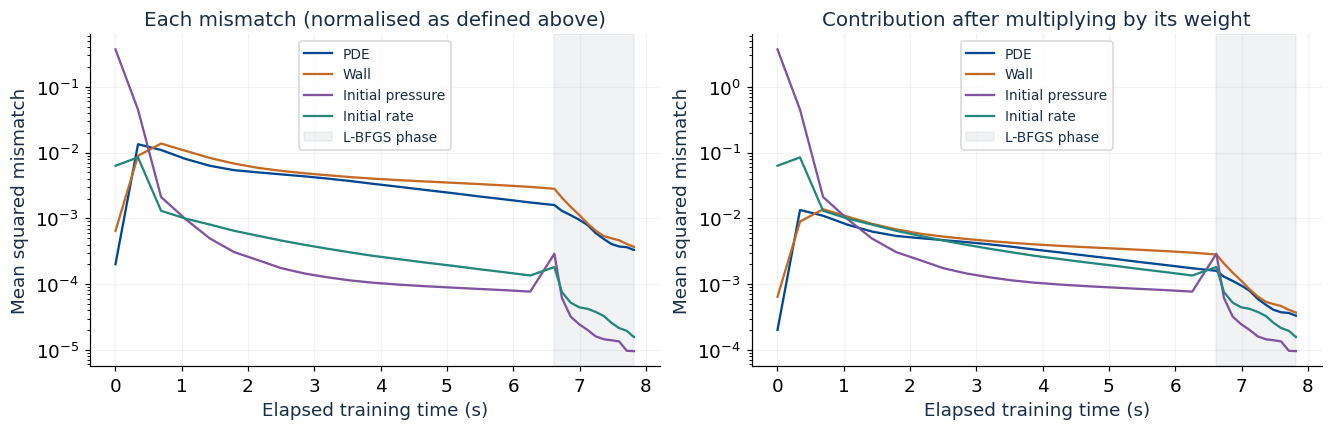

In [37]:
LOSS_LABELS = {"pde": "PDE", "wall": "Wall", "initial_pressure": "Initial pressure", "initial_rate": "Initial rate", "data": "Sensors"}
LOSS_COLOURS = [BLUE, ORANGE, PURPLE, "#23877b", "#a33b55"]

def plot_losses(result):
    h = result["history"]
    elapsed = [row["seconds"] for row in h]
    names = list(LOSS_LABELS) if result["inverse"] else list(LOSS_LABELS)[:4]
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
    for name, colour in zip(names, LOSS_COLOURS):
        values = np.array([row[name] for row in h])
        axs[0].semilogy(elapsed, np.maximum(values, 1e-12), color=colour, label=LOSS_LABELS[name])
        weighted = values*result["weights"][name]
        if result["weights"][name] > 0:
            axs[1].semilogy(elapsed, np.maximum(weighted, 1e-12), color=colour, label=LOSS_LABELS[name])
    adam_rows = [row for row in h if row["stage"] == "Adam"]
    if result["rounds_done"] and adam_rows:
        for ax in axs:
            ax.axvspan(adam_rows[-1]["seconds"], elapsed[-1], color=INK, alpha=.06, label="L-BFGS phase")
    for ax, title in zip(axs, ["Each mismatch (normalised as defined above)", "Contribution after multiplying by its weight"]):
        ax.set(xlabel="Elapsed training time (s)", ylabel="Mean squared mismatch", title=title)
        ax.legend(fontsize=9); ax.grid(alpha=.15)
    return fig

plot_losses(forward)
plt.show()

### Check the answer where we did not train

A separate $41\times21\times13$ grid gives 11,193 space–time queries. We measure

$$\text{relative }L^2\text{ error}=\frac{\sqrt{\sum_i(p_\theta(\mathbf q_i)-p_{\rm ref}(\mathbf q_i))^2}}{\sqrt{\sum_i p_{\rm ref}(\mathbf q_i)^2}}.$$

This is an aggregate over the full grid and time interval, not a maximum local error. We also evaluate the PDE at **1,024 fresh interior points** and normal pressure gradients at **128 fresh points per wall**. The printed residual RMS uses the loss's fixed $\Omega_0^2$ scaling; the wall RMS is the unscaled normal derivative. Different metrics answer different questions.

A small training loss alone is insufficient. Finite points and soft penalties cannot guarantee exact physics everywhere, or reliable extrapolation beyond the training domain and time interval.

In [38]:
def validate(result):
    net,c = result['net'],result['c']
    axes = [torch.linspace(0,2,41),torch.linspace(0,1,21),torch.linspace(0,TMAX,13)]
    q = torch.stack(torch.meshgrid(*axes,indexing='ij'),dim=-1).reshape(-1,3)
    with torch.no_grad():
        prediction, reference = net(q), reference_pressure(q)
        relative = float(torch.linalg.vector_norm(prediction-reference)/torch.linalg.vector_norm(reference))
    fresh = sample_points(1024,128,256,seed=1907)
    qf = fresh['interior'].clone().requires_grad_(True)
    residual = wave_residual(net,qf,c)/OMEGA_REF**2
    qb = fresh['walls'].clone().requires_grad_(True)
    wall_grad = (gradient(net(qb),qb)[:,:2]*fresh['normals']).sum(dim=1)
    return dict(relative_l2=relative, residual_rms=float(residual.detach().square().mean().sqrt()),
                wall_gradient_rms=float(wall_grad.detach().square().mean().sqrt()),
                grid_points=len(q))

def report_results(results):
    lines = ["| Run | Grid relative L² error | Fresh PDE RMS / Ω₀² | Fresh wall-gradient RMS | Time |",
             "|---|---:|---:|---:|---:|"]
    for name, result in results.items():
        score = validate(result)
        lines.append(f"| {name} | {100*score['relative_l2']:.2f}% | {score['residual_rms']:.4f} | {score['wall_gradient_rms']:.4f} | {result['seconds']:.1f} s |")
    display(Markdown("\n".join(lines)))

report_results({"Forward": forward})

| Run | Grid relative L² error | Fresh PDE RMS / Ω₀² | Fresh wall-gradient RMS | Time |
|---|---:|---:|---:|---:|
| Forward | 2.19% | 0.0193 | 0.0608 | 7.8 s |

### Look at more than one instant

Read each row left to right: reference → prediction → signed error (PINN minus reference). Pressure uses the same limits in every panel. Error has its own shared, explicitly labelled scale so small differences remain visible. An error colour is not a pressure amplitude.

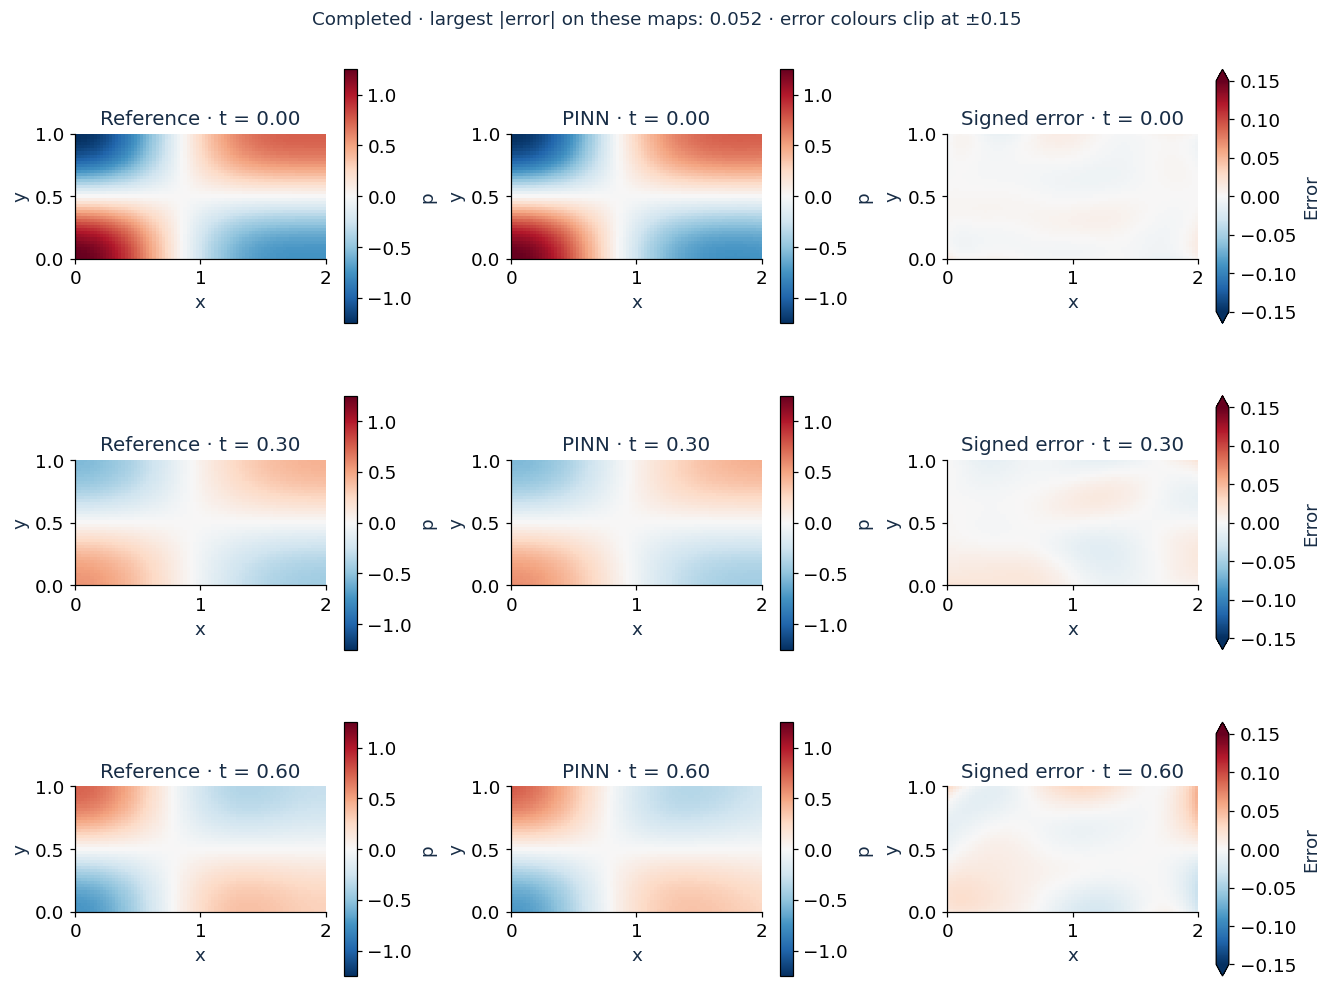

In [39]:
# Fixed error range for all times in this notebook's comparison panels.
ERROR_LIMIT = .15

def compare_maps(result, times=(0., .3, .6)):
    fig, axs = plt.subplots(len(times), 3, figsize=(12, 3.05*len(times)), squeeze=False, layout="constrained")
    largest = 0.
    for row, t in enumerate(times):
        q = map_coordinates(t)
        with torch.no_grad():
            ref, pred = reference_pressure(q).numpy(), result["net"](q).numpy()
        error = pred-ref
        largest = max(largest, float(np.max(np.abs(error))))
        for col, (values, title) in enumerate(zip([ref, pred, error], ["Reference", "PINN", "Signed error"])):
            im = pressure_map(axs[row,col], values, f"{title} · t = {t:.2f}", ERROR_LIMIT if col == 2 else PRESSURE_LIMIT)
            fig.colorbar(im, ax=axs[row,col], label="Error" if col == 2 else "p", shrink=.8,
                         extend="both" if col == 2 else "neither")
    fig.suptitle(f"{result['status']} · largest |error| on these maps: {largest:.3f} · error colours clip at ±{ERROR_LIMIT}", fontsize=12)
    return fig

compare_maps(forward)
plt.show()

### Your virtual microphone

Move the time slider to inspect maps. Move the microphone to compare the pressure history at a location of your choice. The same trained network answers every query; nothing is fitted again.

**Try:** start away from the common nodal line, then set $y=0.5$. Why does that location offer little information about the oscillation? At $x=0$, can the wall pressure be nonzero while its normal derivative is zero?

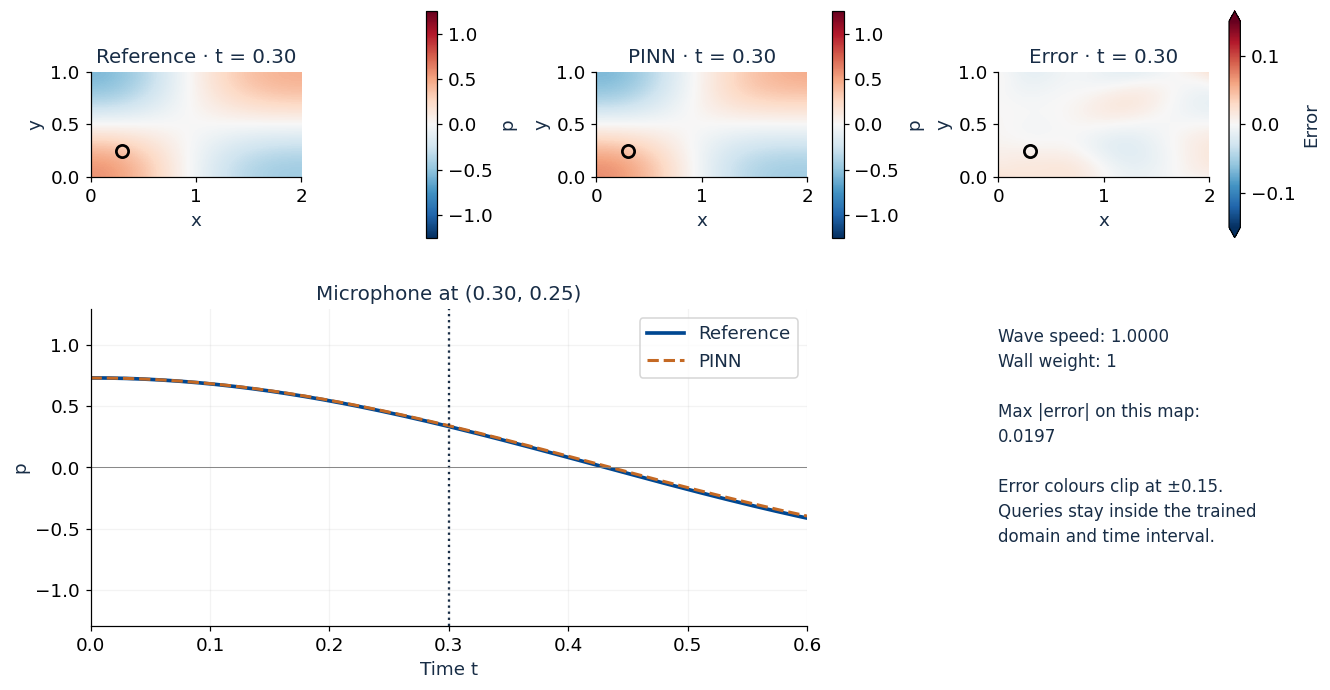

In [40]:
def field_dashboard(result, t=.3, probe_x=.3, probe_y=.25):
    fig = plt.figure(figsize=(12, 6.5), layout="constrained")
    layout = fig.add_gridspec(2, 3, height_ratios=[1, 1.05])
    maps = [fig.add_subplot(layout[0,i]) for i in range(3)]
    q = map_coordinates(t)
    times = np.linspace(0, TMAX, 161)
    qt = trace_coordinates(probe_x, probe_y, times)
    with torch.no_grad():
        ref, pred = reference_pressure(q).numpy(), result["net"](q).numpy()
        ref_t, pred_t = reference_pressure(qt).numpy().ravel(), result["net"](qt).numpy().ravel()
    for i, (ax, values, title) in enumerate(zip(maps, [ref, pred, pred-ref], ["Reference", "PINN", "Error"])):
        im = pressure_map(ax, values, f"{title} · t = {t:.2f}", ERROR_LIMIT if i == 2 else PRESSURE_LIMIT)
        ax.plot(probe_x, probe_y, "o", mfc="none", mec="black", mew=1.8, ms=8)
        fig.colorbar(im, ax=ax, shrink=.75, label="Error" if i == 2 else "p", extend="both" if i == 2 else "neither")
    ax = fig.add_subplot(layout[1,:2])
    ax.plot(times, ref_t, color=BLUE, lw=2.4, label="Reference")
    ax.plot(times, pred_t, color=ORANGE, lw=2, ls="--", label="PINN")
    ax.axvline(t, color=INK, ls=":"); ax.axhline(0, color="grey", lw=.6)
    ax.set(xlabel="Time t", ylabel="p", title=f"Microphone at ({probe_x:.2f}, {probe_y:.2f})", xlim=(0,TMAX), ylim=(-1.3,1.3))
    ax.legend(); ax.grid(alpha=.15)
    info = fig.add_subplot(layout[1,2]); info.axis("off")
    info.text(0, .94, f"Wave speed: {result['c']:.4f}\nWall weight: {result['weights']['wall']:g}\n\nMax |error| on this map:\n{np.max(np.abs(pred-ref)):.4f}\n\nError colours clip at ±{ERROR_LIMIT}.\nQueries stay inside the trained\ndomain and time interval.", va="top", linespacing=1.5, fontsize=11)
    return fig

# Static fallback: edit these arguments and rerun to query a different point/time.
field_dashboard(forward, t=.3, probe_x=.3, probe_y=.25)
plt.show()

In [41]:
# Later cells add the wall experiment and inverse run to this same model menu.
trained_models = {"Forward · known c": forward}
model_menu = widgets.Dropdown(options=list(trained_models), description="Model", layout=widgets.Layout(width="350px"))
field_time = widgets.FloatSlider(value=.3, min=0, max=TMAX, step=.01, description="Time t", continuous_update=False)
probe_x = widgets.FloatSlider(value=.3, min=0, max=2, step=.05, description="Probe x", continuous_update=False)
probe_y = widgets.FloatSlider(value=.25, min=0, max=1, step=.05, description="Probe y", continuous_update=False)
field_image = widgets.Image(format="png", layout=widgets.Layout(max_width="100%"))
def update_field(change=None):
    show_png(field_image, field_dashboard(trained_models[model_menu.value], field_time.value, probe_x.value, probe_y.value))
for control in [model_menu, field_time, probe_x, probe_y]:
    control.observe(update_field, names="value")
update_field()
field_controls = widgets.VBox([widgets.HBox([model_menu, field_time]), widgets.HBox([probe_x, probe_y]), field_image])
display(field_controls)

## B6. Student experiment: what if we forget the walls? · 4 minutes

**Change one thing.** Keep the network seed, initial conditions, interior points and training schedule fixed. Set the wall-loss weight to zero and start a fresh network.

Before running, write a prediction with your neighbour:

1. Will a small interior PDE residual still imply the correct cavity solution?
2. Where do you expect pressure errors to increase?
3. Which independent check would expose the missing condition?

The PDE describes local evolution. The boundaries determine which reflected motion belongs to our cavity. We still evaluate the wall mismatch when its weight is zero, so we can see what training is ignoring.

In [42]:
# TRAINING CELL 2 — change WALL_WEIGHT, predict, then rerun this and the next cell.
WALL_WEIGHT = 0.0          # Default experiment. Later try 0.1 or 10.0.
pinn_experiment = train_pinn(seed=SEED, weights={"wall": WALL_WEIGHT})
trained_models["Experiment · changed wall weight"] = pinn_experiment
model_menu.options = list(trained_models)
update_field()

Adam 600/1,800 · 2.0 s


Adam 1,200/1,800 · 4.1 s


Adam 1,800/1,800 · 6.3 s


Completed · 7.3 s · c = 1.0000


| Run | Grid relative L² error | Fresh PDE RMS / Ω₀² | Fresh wall-gradient RMS | Time |
|---|---:|---:|---:|---:|
| Forward | 2.19% | 0.0193 | 0.0608 | 7.8 s |
| Wall weight 0 | 38.77% | 0.0138 | 0.5473 | 7.3 s |

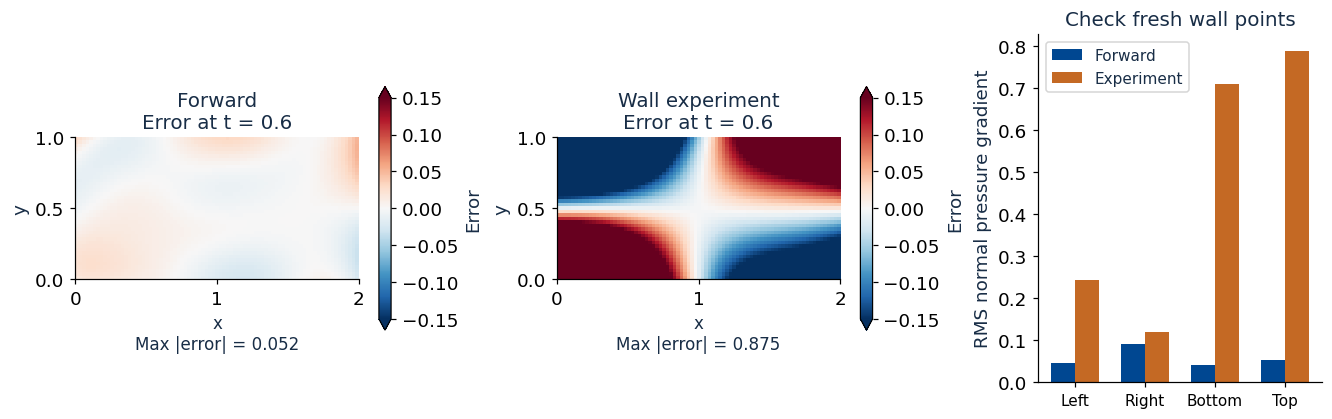

In [43]:
report_results({"Forward": forward, f"Wall weight {WALL_WEIGHT:g}": pinn_experiment})

# Compare at the same instant and probe. Every axis uses the same units and scales.
t = .6
fig, axs = plt.subplots(1, 3, figsize=(12, 3.7), layout="constrained")
q = map_coordinates(t)
for ax, name, result in zip(axs[:2], ["Forward", "Wall experiment"], [forward, pinn_experiment]):
    with torch.no_grad(): error = (result["net"](q)-reference_pressure(q)).numpy()
    im = pressure_map(ax, error, f"{name}\nError at t = {t}", ERROR_LIMIT)
    fig.colorbar(im, ax=ax, shrink=.7, label="Error", extend="both")
    ax.set_xlabel(f"x\nMax |error| = {np.max(np.abs(error)):.3f}", fontsize=11)
fresh = sample_points(1024, 128, 256, seed=1907)
for result, label, colour in [(forward,"Forward",BLUE),(pinn_experiment,"Experiment",ORANGE)]:
    qb = fresh["walls"].clone().requires_grad_(True)
    dn = (gradient(result["net"](qb), qb)[:,:2]*fresh["normals"]).sum(dim=1)
    rms = dn.detach().reshape(4,128).square().mean(dim=1).sqrt().numpy()
    offset = -.17 if label == "Forward" else .17
    axs[2].bar(np.arange(4)+offset, rms, width=.34, color=colour, label=label)
axs[2].set(xticks=np.arange(4), xticklabels=["Left","Right","Bottom","Top"], ylabel="RMS normal pressure gradient", title="Check fresh wall points")
axs[2].tick_params(axis="x",labelsize=10); axs[2].legend(fontsize=10)
plt.show()

<details><summary>Discuss after the wall experiment</summary>

With zero wall weight, the network has no penalty for violating the wall condition. It can fit the initial state and obtain a modest PDE residual while predicting a different field. Compare the grid error and fresh wall gradients, not just the total training loss: changing a weight changes what the total means.

The size and location of the errors depend on training. A very large wall weight is not automatically better either: it can divert effort from initial conditions or the PDE. The goal is a balanced and independently validated solution.

</details>

## B7. Inverse problem: can two microphones reveal the wave speed? · 6 minutes

So far we **knew $c$ and predicted $p$**. Now we have a few pressure measurements, and we want to **estimate $c$ and the field together**.

We place sensors at $(0.3,0.25)$ and $(1.4,0.7)$ and record 16 times per sensor. Both are away from the common nodal line $y=0.5$, and both observe time variation. Two locations reduce our dependence on one weak signal. This is a deliberately simple, noiseless example with known geometry, walls and initial conditions; two sensors are not a general guarantee of identifiability.

We manufacture these 32 observations with $c_{\rm true}=1$. In a real experiment, the microphone would supply the values. Only the sampled observations enter the data loss; the rest of the reference field remains a validation answer.

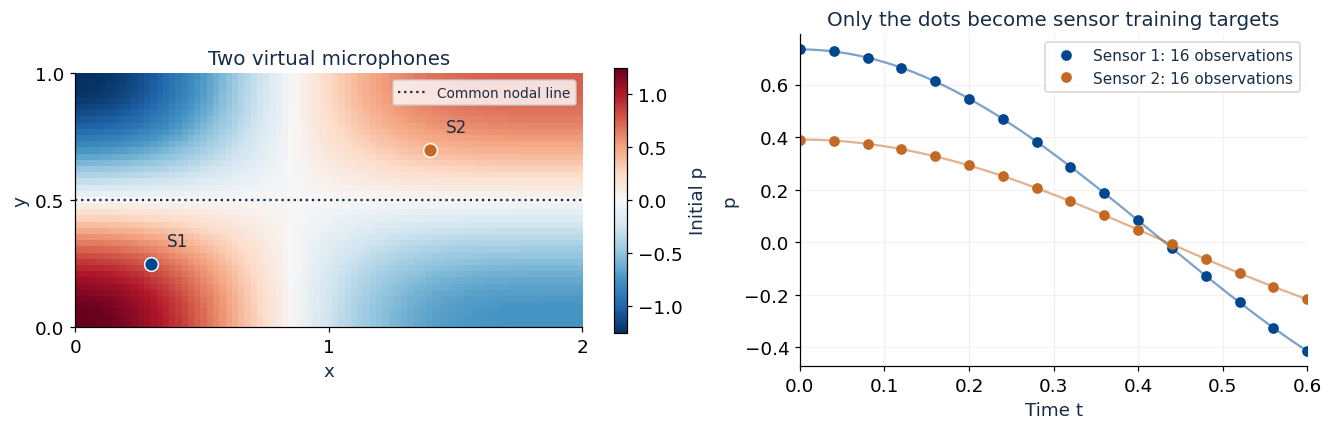

In [44]:
def sensor_observations(c_true=1., count=16, noise_std=0., seed=123):
    locations = [(0.3,.25),(1.4,.7)]
    times = torch.linspace(0,TMAX,count)
    q = torch.cat([torch.stack([torch.full_like(times,x),torch.full_like(times,y),times],dim=1)
                   for x,y in locations])
    clean = reference_pressure(q,c=c_true).detach()
    noise = torch.randn(clean.shape,generator=torch.Generator().manual_seed(seed))*noise_std
    return dict(q=q, p=clean+noise, clean=clean, locations=locations)

observations = sensor_observations(c_true=1., count=16, noise_std=0.)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
im = pressure_map(axs[0], initial_pressure(map_coordinates(0)).numpy(), "Two virtual microphones")
fig.colorbar(im, ax=axs[0], label="Initial p", shrink=.8)
axs[0].axhline(.5, color=INK, ls=":", lw=1.5, label="Common nodal line")
times = np.linspace(0,TMAX,161)
for i, ((x, y), colour) in enumerate(zip(observations["locations"], [BLUE, ORANGE])):
    axs[0].plot(x,y,"o",color=colour,mec="white",ms=9)
    axs[0].text(x+.06,y+.07,f"S{i+1}",color=INK,fontsize=11)
    ids = slice(i*16,(i+1)*16)
    axs[1].plot(times, reference_pressure(trace_coordinates(x,y,times)).numpy(),color=colour,lw=1.5,alpha=.5)
    axs[1].plot(observations["q"][ids,2],observations["p"][ids,0],"o",color=colour,label=f"Sensor {i+1}: 16 observations")
axs[0].legend(loc="upper right",fontsize=9)
axs[1].set(xlabel="Time t",ylabel="p",title="Only the dots become sensor training targets",xlim=(0,TMAX))
axs[1].legend(fontsize=10);axs[1].grid(alpha=.15)
plt.show()

### Same physics, one unknown parameter, one extra loss

We add $\mathcal L_d=\langle(p_\theta(x_s,y_s,t_s)-p_s)^2\rangle$ at the sensor coordinates, with weight $\lambda_d=20$.

$$\mathcal L_{\rm inverse}=\mathcal L_{\rm physics+initial}+20\,\mathcal L_d.$$

We optimise a scalar $a=\log c$ and set $c=\exp(a)>0$. The unknown speed enters the PDE residual; sensor measurements constrain the field's time evolution. Both the network weights and $a$ are updated by the same optimiser.

**No warm start:** the inverse run creates a fresh random network and starts at $c=0.7$. It does not reuse weights from the forward solution with known $c=1$. The two problems share the prescribed initial conditions, which are assumed known.

> **Predict:** when $c$ starts too low, does the model's governing equation favour slower or faster oscillation? What might happen if all sensors sat on the nodal line?

In [45]:
# TRAINING CELL 3 — a fresh network; c is now a positive trainable parameter.
C_START = .7
inverse = train_pinn(inverse=True, observations=observations, c_start=C_START, seed=SEED)
print(f"Initial c: {inverse['initial_c']:.3f} → estimated c: {inverse['c']:.4f} (reference: 1.0000)")
trained_models["Inverse · learned c"] = inverse
model_menu.options = list(trained_models)
update_field()

Adam 600/1,800 · 2.2 s


Adam 1,200/1,800 · 4.4 s


Adam 1,800/1,800 · 6.7 s


Completed · 7.9 s · c = 0.9997


Initial c: 0.700 → estimated c: 0.9997 (reference: 1.0000)


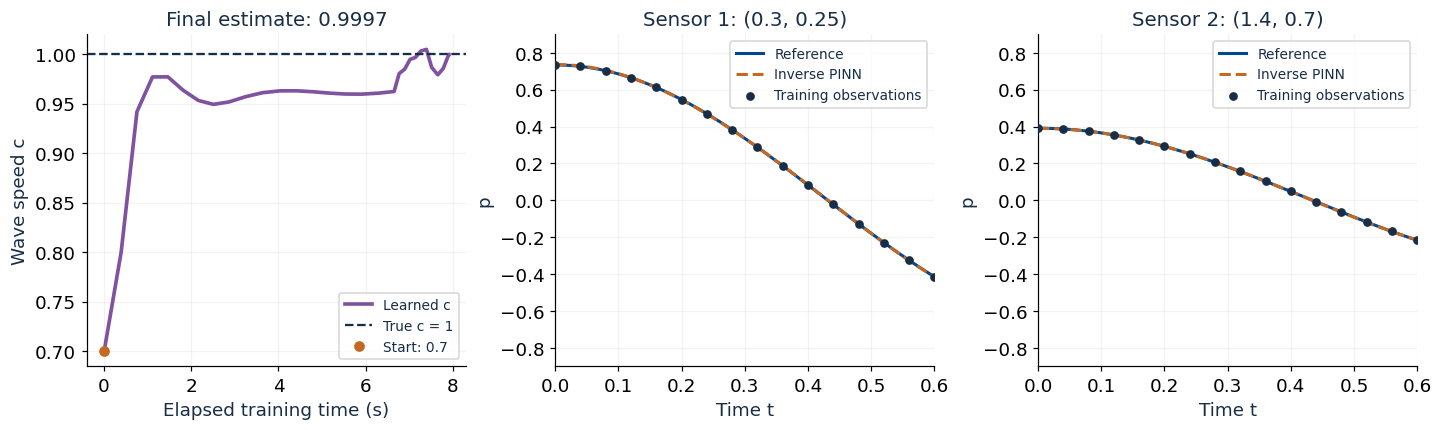

| Run | Grid relative L² error | Fresh PDE RMS / Ω₀² | Fresh wall-gradient RMS | Time |
|---|---:|---:|---:|---:|
| Forward | 2.19% | 0.0193 | 0.0608 | 7.8 s |
| Inverse | 3.82% | 0.0321 | 0.0879 | 7.9 s |

Relative wave-speed error: 0.03%


In [46]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
h = inverse["history"]
axs[0].plot([row["seconds"] for row in h], [row["c"] for row in h],color=PURPLE,lw=2.4,label="Learned c")
axs[0].axhline(1.,color=INK,ls="--",label="True c = 1")
axs[0].plot(h[0]["seconds"],h[0]["c"],"o",color=ORANGE,label=f"Start: {C_START:g}")
axs[0].set(xlabel="Elapsed training time (s)",ylabel="Wave speed c",title=f"Final estimate: {inverse['c']:.4f}")
axs[0].legend(fontsize=9);axs[0].grid(alpha=.15)
times = np.linspace(0,TMAX,161)
for i, (ax, (x,y)) in enumerate(zip(axs[1:],observations["locations"])):
    qt = trace_coordinates(x,y,times)
    with torch.no_grad(): prediction = inverse["net"](qt).numpy().ravel()
    ax.plot(times,reference_pressure(qt).numpy().ravel(),color=BLUE,lw=2,label="Reference")
    ax.plot(times,prediction,color=ORANGE,ls="--",lw=2,label="Inverse PINN")
    ids = slice(i*16,(i+1)*16)
    ax.scatter(observations["q"][ids,2],observations["p"][ids,0],color=INK,s=22,label="Training observations",zorder=4)
    ax.set(xlabel="Time t",ylabel="p",title=f"Sensor {i+1}: ({x}, {y})",xlim=(0,TMAX),ylim=(-.9,.9))
    ax.legend(fontsize=9);ax.grid(alpha=.15)
plt.show()
report_results({"Forward": forward, "Inverse": inverse})
print(f"Relative wave-speed error: {100*abs(inverse['c']-1.):.2f}%")

The sensor fits above concern observations used in training. They are **not an independent test**. The separate grid error in the table checks pressure elsewhere, and the fresh-point residuals check the learned equation and walls. A good speed estimate can coexist with a less accurate pressure field.

For the inverse run, inspect the sensor loss alongside the four physics/initial losses. They compete through the same network and wave-speed parameter.

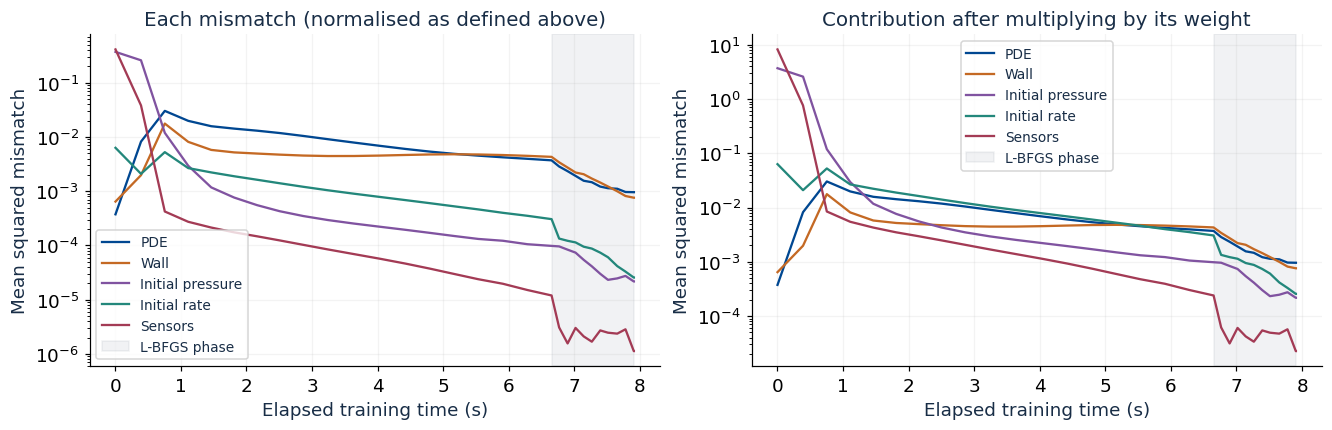

In [47]:
plot_losses(inverse)
plt.show()

### Inspect all three fields

Choose the forward, wall-experiment or inverse model. Move the microphone to a location **other than a training sensor**. Compare pressure histories there, then inspect a wall and the nodal line. A successful fit at two microphones is only part of the evidence.

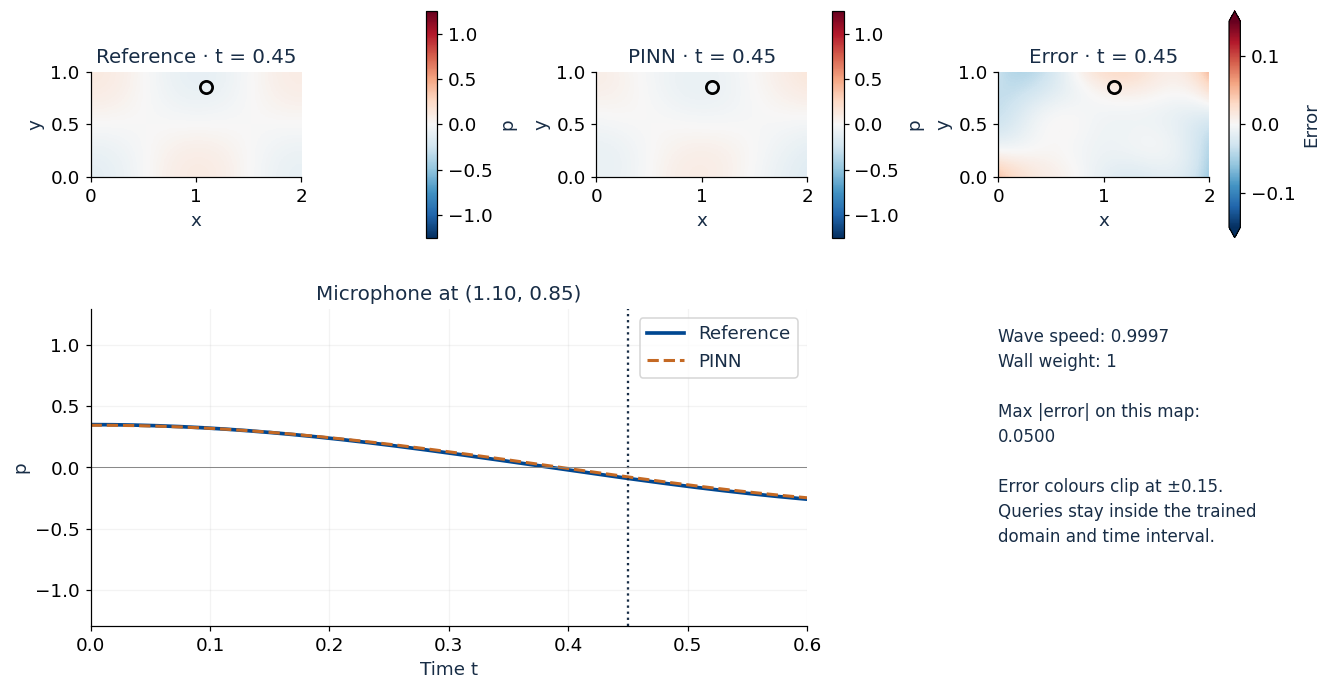

In [48]:
# Reuse the interactive panel; all models are now available in its menu.
model_menu.value = "Inverse · learned c"
display(field_controls)

# A saved static view also makes this result readable without live widgets.
field_dashboard(inverse, t=.45, probe_x=1.1, probe_y=.85)
plt.show()

<details><summary>Discuss after the inverse experiment</summary>

A lower speed gives lower modal frequencies. Informative observations can penalise the resulting timing mismatch while the PDE links field curvature to $c$. At $y=0.5$, both modes are zero for every $c$, so noiseless sensors restricted to that line cannot distinguish wave speeds in this example.

The positivity transform excludes negative speeds, but does not force the value 1. The recovered value depends on information in the observations, the known initial/boundary conditions, and successful optimisation. Noise, a different initial guess, weak sensor signals or model mismatch can make recovery worse.

</details>

## B8. Take away three ideas

1. **A PINN learns a function of coordinates.** Its input derivatives enter the physics loss; its weight derivatives drive optimisation.
2. **The PDE is only part of the problem.** Boundary and initial conditions select the motion we want. We balance and inspect these losses separately, then validate elsewhere.
3. **Observations can identify an unknown parameter.** The inverse problem adds measured values and a trainable $c$; success needs informative data and a suitable physical model.

The GAN learned a distribution of examples and needed a separate physics audit. This PINN brings equations into training through penalties. Those penalties guide learning, but they still require verification. In both cases: inspect what the model actually does.

<a id="optional-experiments"></a>

# Optional experiments · after the 80-minute session

Both sets of trained models are still in memory. You can return to the GAN latent sliders or the PINN microphone panel without restarting or retraining. The two training experiments have distinct result variables, `gan_experiment` and `pinn_experiment`.

The extensions below are outside the session timing. Extra training and CSV export are disabled by default.

## Extra GAN experiments

Choose one if you finish early:

1. **New sampling seed:** generate 400 curves with seed 456. Explain why this changes the sample but not the learned generator.
2. **New training seed:** rerun `train_gan(seed=7)` and compare populations. Expect the latent map to move or reorganise; its axes are not physical parameters.
3. **Less training:** try 1,200 cycles. Compare the curve shapes and family coverage with the baseline.
4. **Explore the tails:** evaluate a latent point such as (4, 4). This is much farther from the commonly sampled region. Inspect both the curve and D's score.
5. **Save your specimen:** the disabled cell below writes a CSV on the current computer or Colab runtime. In Colab, download it through the Files panel.

If you change the reference dataset, rerun scaling and training before using the generator or discriminator. Old weights and a new scaling transform do not form a valid trained model.

In [49]:
SAVE_MY_CURVE = False  # Set True to save the curve you created in Section A9.
if SAVE_MY_CURVE:
    np.savetxt("my_generated_stress_strain.csv", np.column_stack([strain, my_curve]),
               delimiter=",", header="strain_dimensionless,stress_MPa", comments="")
    print("Saved my_generated_stress_strain.csv")
else:
    print("Optional export is off. Your curve remains in the variable my_curve.")

Optional export is off. Your curve remains in the variable my_curve.


## Extra PINN experiments

Choose **one**, predict its effect, and change only that choice in the cell below. Each call creates a fresh network. After training, compare the independent metrics and look at the field with `field_dashboard`.

| Choice | Change | What to investigate |
|---|---|---|
| `"no_initial_pressure"` | Set the initial pressure weight to zero | Can silence satisfy the remaining objectives? Does the network find it? |
| `"fewer_points"` | Use 128 interior points | Is low loss on fewer points enough for low error elsewhere? |
| `"strong_walls"` | Increase the wall weight to 10 | Does improving the walls compete with the other terms? |
| `"noisy_sensors"` | Add pressure noise with standard deviation 0.02 | How sensitive is inferred speed to imperfect observations? |

Removing an initial-pressure term makes the intended solution under-specified. We do not interpret the resulting low loss as a successful forward solution. For the noisy case, keep the initial and boundary conditions known and remember this tests only one noise realisation.

In [50]:
RUN_EXTRA = False  # Change to True only when you choose an optional experiment.
CHOICE = "fewer_points"
if RUN_EXTRA:
    if CHOICE == "no_initial_pressure":
        extra = train_pinn(weights={"initial_pressure": 0.}, seed=SEED)
    elif CHOICE == "fewer_points":
        extra = train_pinn(n_interior=128, seed=SEED)
    elif CHOICE == "strong_walls":
        extra = train_pinn(weights={"wall": 10.}, seed=SEED)
    elif CHOICE == "noisy_sensors":
        noisy = sensor_observations(noise_std=.02, seed=123)
        extra = train_pinn(inverse=True, observations=noisy, c_start=.7, seed=SEED)
        print(f"Estimated c with noise: {extra['c']:.4f}")
    else:
        raise ValueError("Choose one of the four named experiments above.")
    report_results({"Forward baseline": forward, CHOICE: extra})
    plot_losses(extra); plt.show()
    field_dashboard(extra, t=.6, probe_x=.3, probe_y=.25); plt.show()
else:
    print("Optional experiments are off. Choose one, predict, then set RUN_EXTRA = True.")

Optional experiments are off. Choose one, predict, then set RUN_EXTRA = True.


# Runtime, reproducibility and further reading

**Combined notebook verified on 10 October 2026:** all 50 code cells ran in order in **one uninterrupted Jupyter kernel**, with no runtime reset. The GAN latent slider, PINN physics slider, movable microphone and model menu were checked after both parts had run. Returning to the GAN also preserved the PINN predictions.

On an Intel Core Ultra 7 258V, with one CPU thread, Python 3.12.14 and PyTorch 2.6.0+cpu:

| Training cell | Measured training time | Result |
|---|---:|---|
| GAN baseline | 11.4 s | 12,000 update cycles |
| GAN learning-rate experiment | 13.7 s | 12,000 update cycles |
| PINN forward | 7.8 s | 2.19% independent pressure-grid error |
| PINN wall-loss experiment | 7.3 s | 38.77% independent pressure-grid error |
| PINN inverse | 7.9 s | Estimated c = 0.9997 |

The **slowest complete teaching cell, including its output, took 13.9 s**. The complete execution plus extra integration checks took 60.0 s. Peak resident memory of the kernel was approximately 0.50 GiB, including Python, PyTorch and retained results. These measurements support keeping one runtime for this small session.

These are **local CPU measurements, not measurements from Google Colab**. Every training call prints its elapsed time and has a 110-second budget. A slow run can stop with a clearly labelled partial result; inspect its completed updates before comparing it with a full run. This is a practical guard, not a hard operating-system deadline. Package installation and plotting add overhead.

All five default training runs start fresh models with explicit seeds. Data generation and evaluation sampling also use explicit seeds. The PINN point set stays fixed between its baseline and wall experiment. Different library versions or processors can still change floating-point results and optimisation. Saved outputs illustrate one actual run; they do not guarantee identical results on every computer.

We retain the trained models across the transition so earlier controls keep working. This session does not need a runtime reset. Resetting would discard those models and require rerunning earlier cells.

### Additional inverse-problem check

Three separate CPU benchmarks of the PINN inverse problem used fresh-network seeds 20261013, 7 and 42. They recovered $c=0.9871$–$0.9997$ from an initial value of 0.7, with a maximum speed error of 1.29%. Pressure-field grid errors ranged from 3.8% to 6.4%. These tests used the stated noiseless sensors and known initial/boundary conditions; they do not establish general robustness.

We can already sample the bilinear material law directly, and we have an analytical acoustic solution. These deliberately small problems let us inspect the learning methods. They are not claims that a GAN is needed for this synthetic dataset or that a PINN outperforms a conventional acoustic solver.

### Sources and relation to the lecture

- Goodfellow et al., [Generative Adversarial Networks (2014)](https://arxiv.org/abs/1406.2661): generator/discriminator objectives.
- PyTorch, [GAN training tutorial](https://docs.pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html): alternating updates and detaching generated samples for D.
- PyTorch, [BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html): the discriminator's numerically stable binary classification loss.
- [Original PINN project and examples](https://github.com/maziarraissi/PINNs): forward and inverse formulations.
- PyTorch, [automatic differentiation](https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad.html): input derivatives and `create_graph`.

The KTH AI retreat CNN and GANs/PINNs lecture material supplies the teaching context. We follow the CNN hands-on's physical introductions, labelled diagrams, executable examples and inspection of learned behaviour. All reference data and diagrams are constructed here for teaching.